# BÀI TẬP LỚN HỌC MÁY (MACHINE LEARNING) - PTIT

## ĐỀ TÀI: DỰ ĐOÁN VÀ ĐÁNH GIÁ NGUY CƠ BỆNH TIM MẠCH (HEALTHCARE AND PATIENT RISK ANALYSIS)

### Nghiên cứu Đa Tập Dữ Liệu (Multi-Dataset Study), Đánh Giá Xuyên Miền (Cross-Domain), Trôi Dữ Liệu (Data Drift) và Khung Dự Đoán Tin Cậy (Trustworthy AI)

---

### 1. Giới thiệu & Mục tiêu nghiên cứu

Bệnh tim mạch (Cardiovascular Diseases - CVD) là nguyên nhân gây tử vong hàng đầu trên toàn cầu. Việc áp dụng Học Máy để sàng lọc nguy cơ sớm cho bệnh nhân có ý nghĩa sống còn. Tuy nhiên, trong y tế thực tế, mô hình huấn luyện trên một bệnh viện/quần thể (population) hiếm khi hoạt động hoàn hảo khi triển khai tại một bệnh viện khác do hiện tượng **Trôi phân phối dữ liệu (Distribution Shift / Covariate Shift)** và **Lệch tỷ lệ nền (Base-rate / Prior Shift)**.

Báo cáo nghiên cứu và mã nguồn này giải quyết trọn vẹn 4 yêu cầu của Bài tập lớn:

1. **Sử dụng từ 2 bộ dữ liệu y tế độc lập**:
   - **Tập A: Framingham Heart Study** (4.240 bệnh nhân, Mỹ, tỷ lệ bệnh ~15%, bài toán dự đoán biến cố tim mạch 10 năm - _TenYearCHD_).
   - **Tập B: Cardiovascular Disease Dataset** (70.000 bệnh nhân, Đông Âu, tỷ lệ bệnh ~50%, bài toán chẩn đoán hiện diện bệnh tim mạch - _cardio_).
2. **Tổng hợp và so sánh toàn diện các mô hình học máy**:
   - Baseline
   - _Logistic Regression_
   - _K-Nearest Neighbors (KNN)_
   - _Gaussian Naive Bayes_
   - _Random Forest_
   - _XGBoost_
   - _Support Vector Machine (SVM)_
3. **Phân tích lỗi chuyên sâu, đánh giá đúng chuẩn y tế (Model Assessment)**:
   - Phân chia 60% Train / 20% Validation / 20% Test phân tầng (_Stratified Split_), chống rò rỉ dữ liệu (_Data Leakage_) bằng `Pipeline` độc lập cho từng mô hình.
   - Đường cong học tập (_Learning Curves_ - Slide Model Assessment p. 30) phân tích hiện tượng Overfitting/Underfitting.
   - Tối ưu hóa ngưỡng quyết định (_Threshold Tuning_ - Slide Model Assessment p. 34–36 & p. 51) theo bài toán y tế: Giữ nguyên xác suất hậu nghiệm chuẩn để chọn ngưỡng $p^*$ đạt $\text{Recall} \ge 0.80$ và tối đa hóa Precision nhằm giảm chi phí $\text{Cost} = FP + 5 \times FN$.
   - Ước lượng khoảng tin cậy 95% bằng phương pháp Bootstrap (_Bootstrap 95% Confidence Interval_ - Slide Model Assessment p. 45).
4. **Điểm cộng sáng tạo (Bonus ML ngoài chương trình giảng dạy)**:
   - **Kiểm định Đối nghịch (Adversarial Validation)**: Sử dụng XGBoost phân biệt nguồn gốc dữ liệu nhằm định lượng mức độ trôi phân phối (_Data Drift_) và xếp hạng các đặc trưng biến đổi mạnh nhất.
   - **Hiệu chuẩn xác suất hậu nghiệm (Post-hoc Probability Calibration)**: Áp dụng Platt Scaling và Isotonic Regression để khắc phục sai lệch tỷ lệ nền khi chuyển giao mô hình xuyên miền (_Cross-domain Transfer_).
   - **Giải thích mô hình cục bộ & toàn cục với SHAP (SHapley Additive exPlanations)**: Bóc tách cơ chế ra quyết định của mô hình cây và truy nguyên các trường hợp dự đoán sai âm tính (_False Negatives_).
   - **Dự đoán Phù hợp Đảm bảo Độ phủ (Conformal Prediction via MAPIE)**: Cung cấp tập dự đoán có bảo chứng thống kê $\{0\}, \{1\}$ hoặc $\{0, 1\}$ (chuyển hội chẩn bác sĩ khi bất định).


In [1]:
# [Setup & Reproducibility]
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Sklearn imports
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    brier_score_loss,
    confusion_matrix,
    classification_report,
)

# Optional scikit-learn 1.6+ FrozenEstimator support
try:
    from sklearn.frozen import FrozenEstimator
except ImportError:
    FrozenEstimator = None

# XGBoost, SHAP & MAPIE
import xgboost as xgb
from xgboost import XGBClassifier
import shap
import mapie

try:
    from mapie.classification import SplitConformalClassifier
except ImportError:
    from mapie.classification import MapieClassifier as SplitConformalClassifier

# Global configuration
warnings.filterwarnings("ignore")
np.random.seed(42)
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def save_fig(fig, filename, dpi=200):
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f" Saved figure: {path} (DPI={dpi})")


print(
    f"Environment ready | Python {sys.version.split()[0]} | "
    f"sklearn {sklearn.__version__} | xgboost {xgb.__version__} | "
    f"shap {shap.__version__} | mapie {mapie.__version__}"
)


Environment ready | Python 3.12.10 | sklearn 1.9.1 | xgboost 2.1.4 | shap 0.49.1 | mapie 1.6.0


## 2. Tiền xử lý & Căn chỉnh lược đồ (Schema Harmonization)

### [Cũ - Slide 1 & Slide 3]

Hai tập dữ liệu xuất phát từ các nguồn điều tra dịch tễ học và lâm sàng khác nhau với các đơn vị và quy cách đo lường khác biệt:

1. **Lọc dữ liệu ngoại lai sinh học bất khả thi (Cardio Dataset)**:
   - Huyết áp tâm thu (`ap_hi`): $60 \le \text{ap\_hi} \le 250$ mmHg.
   - Huyết áp tâm trương (`ap_lo`): $30 \le \text{ap\_lo} \le 160$ mmHg.
   - Điều kiện sinh lý bắt buộc: $\text{ap\_hi} > \text{ap\_lo}$.
   - Chiều cao (`height`): $120 \le \text{height} \le 220$ cm; Cân nặng (`weight`): $30 \le \text{weight} \le 200$ kg.
2. **Căn chỉnh về 8 đặc trưng lâm sàng dùng chung theo 3 nhóm chuẩn không gian metric**:
   - **Nhóm biến số liên tục (`NUM_FEATURES`)** — điền khuyết `median` + chuẩn hóa `StandardScaler`:
     - `age`: Tuổi bệnh nhân (quy đổi thống nhất về số năm thực).
     - `bmi`: Chỉ số khối cơ thể $\text{BMI} = \frac{\text{weight (kg)}}{(\text{height (m)})^2}$.
     - `sys_bp`: Huyết áp tâm thu (mmHg).
     - `dia_bp`: Huyết áp tâm trương (mmHg).
   - **Nhóm biến thứ bậc (`ORD_FEATURES`)** — điền khuyết `most_frequent` + chuẩn hóa `StandardScaler` để đồng nhất khoảng cách Euclidean (KNN) và phạt điều chuẩn $L_2$ (Logistic Regression, SVM):
     - `chol_level`: Mức Cholesterol theo chuẩn AHA/NCEP ATP III ($1$: Bình thường $<200$, $2$: Ranh giới cao $200\text{–}239$, $3$: Cao $\ge 240$ mg/dL).
     - `gluc_level`: Mức Glucose máu lúc đói theo chuẩn ADA ($1$: Bình thường $<100$, $2$: Tiền đái tháo đường $100\text{–}125$, $3$: Đái tháo đường $\ge 126$ mg/dL).
   - **Nhóm biến nhị phân (`BIN_FEATURES`)** — điền khuyết `most_frequent`, giữ nguyên mã hóa $\{0, 1\}$:
     - `is_male`: Giới tính nhị phân ($1 = \text{Nam}, 0 = \text{Nữ}$).
     - `smoker`: Trạng thái hút thuốc ($1 = \text{Có}, 0 = \text{Không}$).
3. **Phân chia 60% Train / 20% Validation / 20% Test** phân tầng (_Stratified_). Việc điền giá trị thiếu (_Imputation_) và chuẩn hóa (_Standardization_) được đóng gói hoàn toàn trong `Pipeline` độc lập cho từng mô hình trên tập Train để loại bỏ 100% rủi ro rò rỉ dữ liệu (_Data Leakage_).


In [2]:
# [Data Loading & Biological Filtering]
df_framingham_raw = pd.read_csv("data/raw/framingham.csv")
df_cardio_raw = pd.read_csv("data/raw/cardio_train.csv", sep=";")

print(f"Raw Framingham shape: {df_framingham_raw.shape}")
print(f"Raw Cardio shape:     {df_cardio_raw.shape}")

# Biological sanity filtering for Cardio dataset
valid_cardio = (
    (df_cardio_raw["ap_hi"] >= 60)
    & (df_cardio_raw["ap_hi"] <= 250)
    & (df_cardio_raw["ap_lo"] >= 30)
    & (df_cardio_raw["ap_lo"] <= 160)
    & (df_cardio_raw["ap_hi"] > df_cardio_raw["ap_lo"])
    & (df_cardio_raw["height"] >= 120)
    & (df_cardio_raw["height"] <= 220)
    & (df_cardio_raw["weight"] >= 30)
    & (df_cardio_raw["weight"] <= 200)
)
df_cardio_filtered = df_cardio_raw[valid_cardio].copy()
removed_rows = len(df_cardio_raw) - len(df_cardio_filtered)
print(
    f"Cardio filtered: Removed {removed_rows} invalid physiological rows ({removed_rows / len(df_cardio_raw) * 100:.2f}%). Remaining: {len(df_cardio_filtered)}"
)


Raw Framingham shape: (4240, 16)
Raw Cardio shape:     (70000, 13)
Cardio filtered: Removed 1381 invalid physiological rows (1.97%). Remaining: 68619


In [3]:
# [Harmonization Function & Unified 3-Group Feature Schema]
NUM_FEATURES = ["age", "bmi", "sys_bp", "dia_bp"]
ORD_FEATURES = ["chol_level", "gluc_level"]
BIN_FEATURES = ["is_male", "smoker"]
COMMON_FEATURES = NUM_FEATURES + ORD_FEATURES + BIN_FEATURES


def harmonize_framingham(df):
    clean = pd.DataFrame(index=df.index)
    clean["age"] = df["age"].astype(float)
    clean["bmi"] = df["BMI"].astype(float)
    clean["sys_bp"] = df["sysBP"].astype(float)
    clean["dia_bp"] = df["diaBP"].astype(float)
    clean["is_male"] = df["male"].astype(int)
    clean["smoker"] = df["currentSmoker"].astype(int)

    # Categorize totChol (mg/dL) based on AHA/NCEP ATP III guidelines
    # <200: 1 (Normal), 200-239: 2 (Borderline High), >=240: 3 (High)
    clean["chol_level"] = np.select(
        [df["totChol"].isna(), df["totChol"] < 200, df["totChol"] < 240],
        [np.nan, 1.0, 2.0],
        default=3.0,
    )

    # Categorize fasting glucose (mg/dL) based on ADA guidelines
    # <100: 1 (Normal), 100-125: 2 (Prediabetes), >=126: 3 (Diabetes)
    clean["gluc_level"] = np.select(
        [df["glucose"].isna(), df["glucose"] < 100, df["glucose"] < 126],
        [np.nan, 1.0, 2.0],
        default=3.0,
    )

    clean["target"] = df["TenYearCHD"].astype(int)
    return clean[COMMON_FEATURES + ["target"]]


def harmonize_cardio(df):
    clean = pd.DataFrame(index=df.index)
    # Cardio age is in days -> convert to years
    clean["age"] = (df["age"] / 365.25).round(1)
    # BMI calculation: weight (kg) / (height (m))^2
    clean["bmi"] = (df["weight"] / ((df["height"] / 100.0) ** 2)).round(2)
    clean["sys_bp"] = df["ap_hi"].astype(float)
    clean["dia_bp"] = df["ap_lo"].astype(float)
    # Cardio gender: 2 = Male, 1 = Female -> convert to binary is_male: 1, 0
    clean["is_male"] = (df["gender"] == 2).astype(int)
    clean["smoker"] = df["smoke"].astype(int)
    clean["chol_level"] = df["cholesterol"].astype(float)
    clean["gluc_level"] = df["gluc"].astype(float)
    clean["target"] = df["cardio"].astype(int)
    return clean[COMMON_FEATURES + ["target"]]


df_A = harmonize_framingham(df_framingham_raw)
df_B = harmonize_cardio(df_cardio_filtered)

print("--- HARMONIZED DATASET OVERVIEW ---")
print(
    f"Dataset A (Framingham): {df_A.shape[0]} rows | Target Rate: {df_A['target'].mean() * 100:.2f}% (Positives: {df_A['target'].sum()})"
)
print(
    f"Dataset B (Cardio):     {df_B.shape[0]} rows | Target Rate: {df_B['target'].mean() * 100:.2f}% (Positives: {df_B['target'].sum()})"
)
print(f"Numeric Features ({len(NUM_FEATURES)}): {NUM_FEATURES}")
print(f"Ordinal Features ({len(ORD_FEATURES)}): {ORD_FEATURES}")
print(f"Binary Features  ({len(BIN_FEATURES)}): {BIN_FEATURES}")


--- HARMONIZED DATASET OVERVIEW ---
Dataset A (Framingham): 4240 rows | Target Rate: 15.19% (Positives: 644)
Dataset B (Cardio):     68619 rows | Target Rate: 49.47% (Positives: 33945)
Numeric Features (4): ['age', 'bmi', 'sys_bp', 'dia_bp']
Ordinal Features (2): ['chol_level', 'gluc_level']
Binary Features  (2): ['is_male', 'smoker']


--- MISSING VALUE AUDIT ---


,Missing_A_Count,Missing_A_Pct(%),Missing_B_Count,Missing_B_Pct(%)
age,0,0.00,0,0.0
bmi,19,0.45,0,0.0
sys_bp,0,0.00,0,0.0
dia_bp,0,0.00,0,0.0
chol_level,50,1.18,0,0.0
gluc_level,388,9.15,0,0.0
is_male,0,0.00,0,0.0
smoker,0,0.00,0,0.0


 Saved figure: figures\fig1_eda_distributions.png (DPI=200)


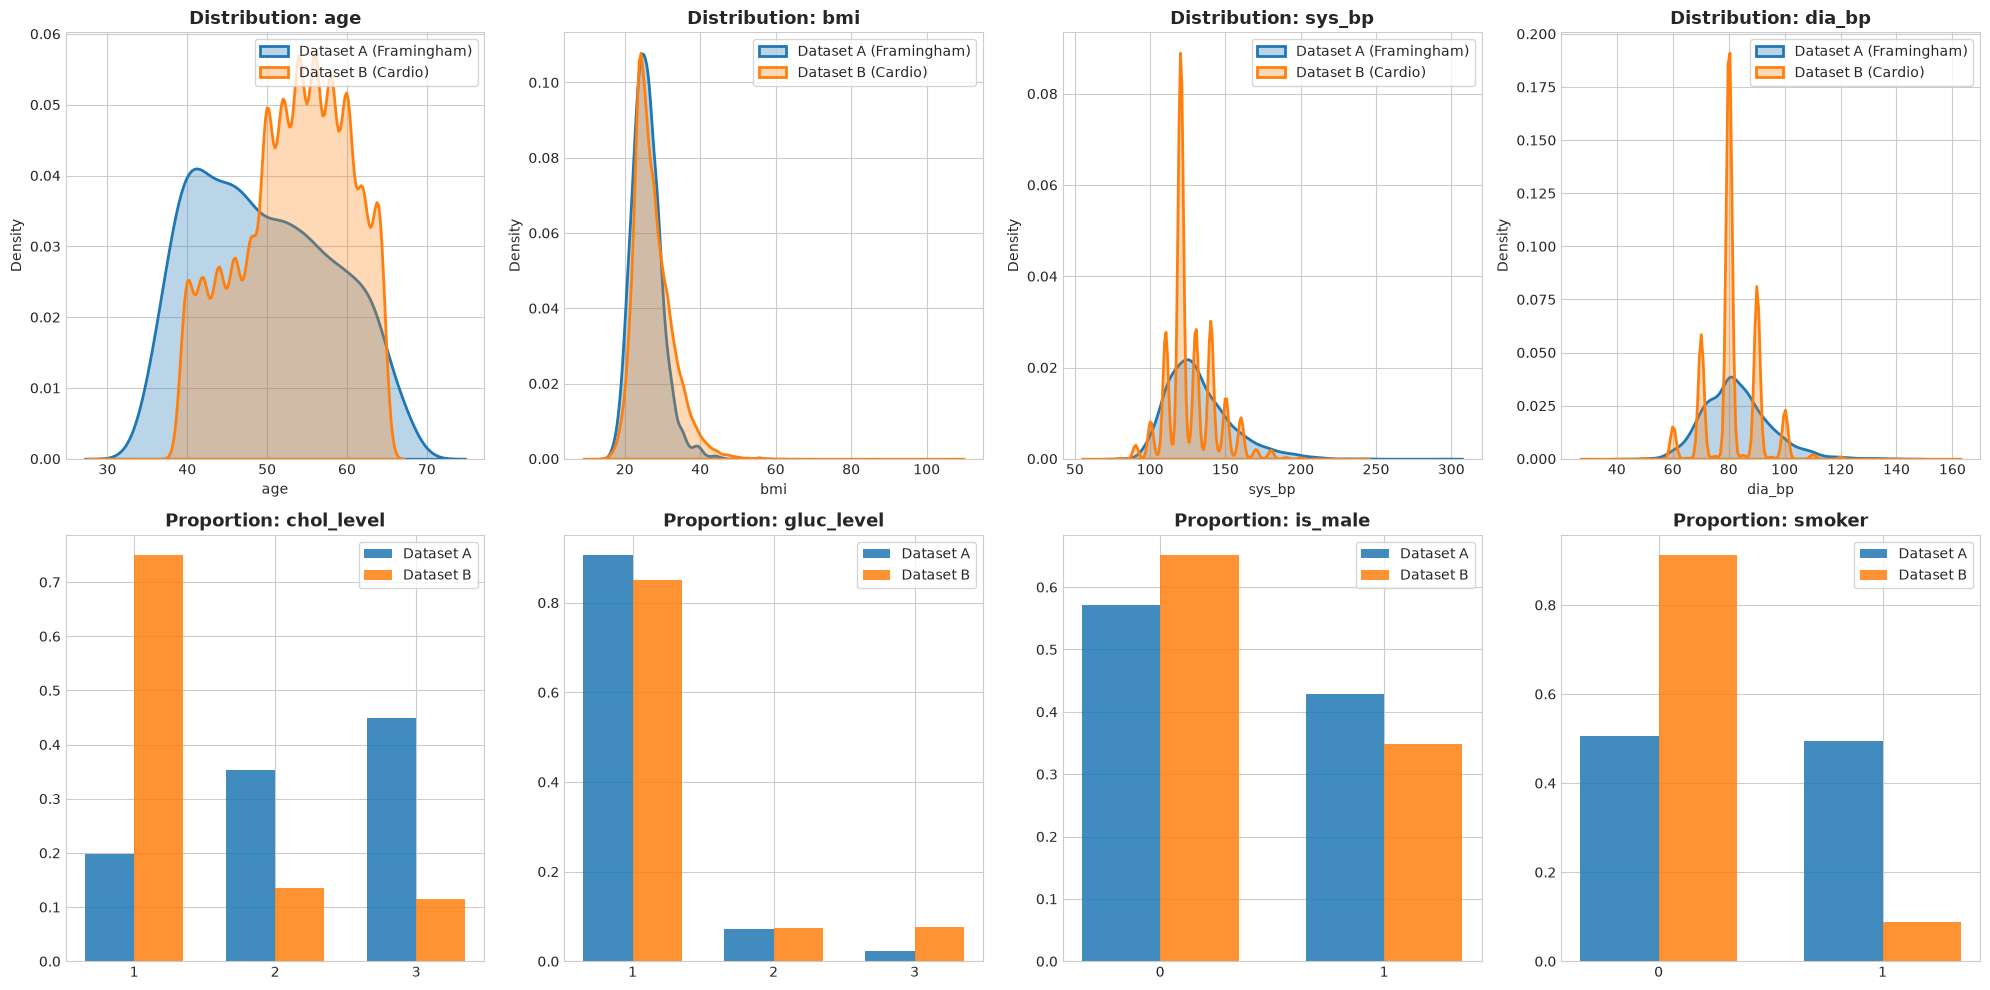

 Saved figure: figures\fig2_correlation_matrix.png (DPI=200)


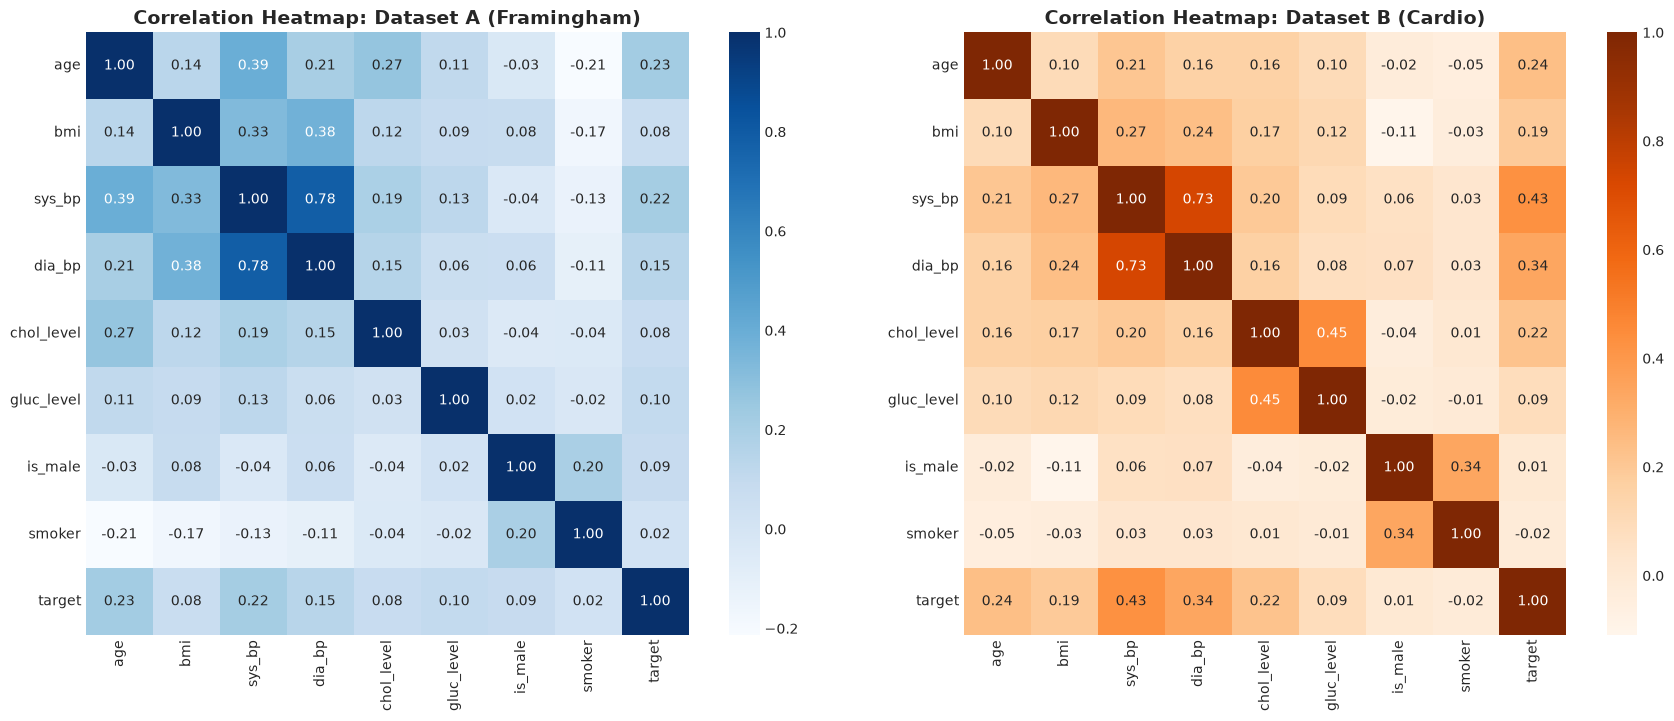

In [4]:
# [Exploratory Data Analysis & Missingness Audit]
missing_audit = pd.DataFrame(
    {
        "Missing_A_Count": df_A[COMMON_FEATURES].isna().sum(),
        "Missing_A_Pct(%)": (df_A[COMMON_FEATURES].isna().mean() * 100).round(2),
        "Missing_B_Count": df_B[COMMON_FEATURES].isna().sum(),
        "Missing_B_Pct(%)": (df_B[COMMON_FEATURES].isna().mean() * 100).round(2),
    }
)
print("--- MISSING VALUE AUDIT ---")
display(missing_audit)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(COMMON_FEATURES):
    ax = axes[i]
    if col in NUM_FEATURES:
        sns.kdeplot(
            data=df_A[col].dropna(),
            ax=ax,
            label="Dataset A (Framingham)",
            color="#1f77b4",
            fill=True,
            alpha=0.3,
            lw=2,
        )
        sns.kdeplot(
            data=df_B[col].dropna(),
            ax=ax,
            label="Dataset B (Cardio)",
            color="#ff7f0e",
            fill=True,
            alpha=0.3,
            lw=2,
        )
        ax.set_title(f"Distribution: {col}", fontsize=13, fontweight="bold")
    else:
        counts_A = df_A[col].value_counts(normalize=True).sort_index()
        counts_B = df_B[col].value_counts(normalize=True).sort_index()
        cats = sorted(list(set(counts_A.index).union(set(counts_B.index))))
        bar_w = 0.35
        x = np.arange(len(cats))
        ax.bar(
            x - bar_w / 2,
            [counts_A.get(c, 0) for c in cats],
            bar_w,
            label="Dataset A",
            color="#1f77b4",
            alpha=0.85,
        )
        ax.bar(
            x + bar_w / 2,
            [counts_B.get(c, 0) for c in cats],
            bar_w,
            label="Dataset B",
            color="#ff7f0e",
            alpha=0.85,
        )
        ax.set_xticks(x)
        ax.set_xticklabels([str(int(c)) if not pd.isna(c) else "NA" for c in cats])
        ax.set_title(f"Proportion: {col}", fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
save_fig(fig, "fig1_eda_distributions.png")
plt.show()

# Correlation Heatmap for Both Datasets
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(
    df_A[COMMON_FEATURES + ["target"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    ax=ax1,
    cbar=True,
    square=True,
)
ax1.set_title(
    "Correlation Heatmap: Dataset A (Framingham)", fontsize=14, fontweight="bold"
)

sns.heatmap(
    df_B[COMMON_FEATURES + ["target"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="Oranges",
    ax=ax2,
    cbar=True,
    square=True,
)
ax2.set_title("Correlation Heatmap: Dataset B (Cardio)", fontsize=14, fontweight="bold")

plt.tight_layout()
save_fig(fig, "fig2_correlation_matrix.png")
plt.show()


In [ ]:
# [Train / Validation / Test Splitting: 60 / 20 / 20 Stratified]
def split_data(df, target_col="target", random_state=42):
    X = df[COMMON_FEATURES].copy()
    y = df[target_col].copy()

    # 60% Train, 40% Temporary (Val + Test)
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.40, stratify=y, random_state=random_state
    )
    # Split Temporary equally: 50/50 -> 20% Val, 20% Test
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=random_state
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


X_train_A, X_val_A, X_test_A, y_train_A, y_val_A, y_test_A = split_data(df_A)
X_train_B, X_val_B, X_test_B, y_train_B, y_val_B, y_test_B = split_data(df_B)

print(
    f"Dataset A Splits -> Train: {len(X_train_A)} ({y_train_A.mean() * 100:.1f}% pos) | Val: {len(X_val_A)} ({y_val_A.mean() * 100:.1f}% pos) | Test: {len(X_test_A)} ({y_test_A.mean() * 100:.1f}% pos)"
)
print(
    f"Dataset B Splits -> Train: {len(X_train_B)} ({y_train_B.mean() * 100:.1f}% pos) | Val: {len(X_val_B)} ({y_val_B.mean() * 100:.1f}% pos) | Test: {len(X_test_B)} ({y_test_B.mean() * 100:.1f}% pos)"
)


def make_preprocessor():
    """Create a fresh, state-isolated 3-branch ColumnTransformer (num, ord, bin) per pipeline."""
    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                NUM_FEATURES,
            ),
            (
                "ord",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                ORD_FEATURES,
            ),
            (
                "bin",
                Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))]),
                BIN_FEATURES,
            ),
        ],
        verbose_feature_names_out=False,
    )


print(
    "Preprocessing factory make_preprocessor() initialized (3-branch metric-safe & state-isolated)."
)


Dataset A Splits -> Train: 2544 (15.2% pos) | Val: 848 (15.2% pos) | Test: 848 (15.2% pos)
Dataset B Splits -> Train: 41171 (49.5% pos) | Val: 13724 (49.5% pos) | Test: 13724 (49.5% pos)
Preprocessing factory make_preprocessor() initialized (3-branch metric-safe & state-isolated).


## 3. Huấn luyện & Đánh giá In-Domain (Mô hình trên lớp)

### [Cũ - Slide 1 đến Slide 7 & Model Assessment]

Trong phần này, chúng ta huấn luyện và so sánh toàn diện 7 thuật toán học máy kinh điển được giảng dạy trong học phần:

1. **Dummy Baseline** (_Slide 1 & Model Assessment_): Chiến lược `most_frequent`.
2. **Logistic Regression** (_Slide 2 & Slide 3_): Điều chuẩn L2 (`C=1.0`), giữ nguyên xác suất hậu nghiệm chuẩn để phục vụ tối ưu ngưỡng quyết định y tế và kiểm định hiệu chuẩn xuyên miền.
3. **K-Nearest Neighbors (KNN)** (_Slide 4_): Tối ưu số láng giềng $k=15$ với khoảng cách Euclidean và trọng số khoảng cách (`weights='distance'`).
4. **Gaussian Naive Bayes** (_Slide 5_): Ước lượng xác suất phân phối Gauss với giả thiết độc lập có điều kiện.
5. **Random Forest** (_Slide 6_): Tập hợp 100 cây quyết định, giới hạn độ sâu `max_depth=8`.
6. **XGBoost Classifier** (_Slide 6_): Gradient Boosting với `learning_rate=0.05`, `max_depth=4`, giữ phân phối xác suất gốc trung thực.
7. **Support Vector Machine (SVM)** (_Slide 7_):
   - Với Dataset A (4.2k mẫu): `SVC(kernel='rbf', probability=True, class_weight='balanced')` (Platt scaling nội bộ chuẩn hóa lại xác suất từ siêu phẳng phân tách).
   - Với Dataset B (70k mẫu): Huấn luyện Kernel SVM thông thường có độ phức tạp tính toán $O(N^2)$ đến $O(N^3)$, sẽ mất hàng giờ. Theo đúng lý thuyết Slide 7, ta áp dụng xấp xỉ hạt nhân **Nystroem Kernel Approximation** kết hợp **SGDClassifier(loss='log_loss')**.

### Tiêu chí Đánh giá Lâm sàng (Medical Assessment Metrics):

- Trong sàng lọc y tế, **Âm tính giả (False Negative - FN)** là hiểm họa chết người (bệnh nhân mắc bệnh nhưng bị chẩn đoán nhầm là khỏe mạnh và không được điều trị). Do đó, chi phí sai lầm được định nghĩa:
  $$\text{Cost} = 1 \times FP + 5 \times FN$$
- **Tối ưu ngưỡng quyết định (_Threshold Tuning_ - Model Assessment p. 34–36 & p. 51)**: Tìm ngưỡng $p^*$ trên tập Validation thỏa mãn điều kiện y tế $\text{Recall} \ge 0.80$ và tối đa hóa Precision (nếu Precision bằng nhau, chọn ngưỡng lớn nhất), sau đó giữ cố định $p^*$ để đánh giá trên tập Test.
- **Bootstrap 95% Confidence Interval** (_Model Assessment Slide p. 45_): Đánh giá tính vững của chỉ số ROC-AUC qua 1000 lần lấy mẫu hoàn lại.
- **Learning Curves** (_Model Assessment Slide p. 30_): Khảo sát động thái lỗi huấn luyện và kiểm định theo kích thước dữ liệu.


In [6]:
# [Model Definitions & Pipeline Assembly]
def get_model_zoo(dataset_name="A"):
    models = {}

    # 1. Dummy Baseline (Slide 1)
    models["Dummy_Baseline"] = DummyClassifier(strategy="most_frequent")

    # 2. Logistic Regression (Slide 2 & 3) - keep calibrated posterior probabilities
    models["Logistic_Regression"] = LogisticRegression(
        penalty="l2", C=1.0, max_iter=1000, random_state=42
    )

    # 3. K-Nearest Neighbors (Slide 4)
    models["KNN"] = KNeighborsClassifier(n_neighbors=15, weights="distance")

    # 4. Gaussian Naive Bayes (Slide 5)
    models["Gaussian_NB"] = GaussianNB()

    # 5. Random Forest (Slide 6)
    models["Random_Forest"] = RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
    )

    # 6. XGBoost (Slide 6) - un-reweighted probabilities for clean calibration & threshold tuning
    models["XGBoost"] = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    )

    # 7. Support Vector Machine (Slide 7)
    if dataset_name == "A":
        # SVC uses balanced margin for 15% minority class; probability=True applies internal Platt scaling
        models["SVM"] = SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            class_weight="balanced",
            random_state=42,
        )
    else:
        # Large 70k Cardio dataset: Nystroem Kernel Approximation + SGDClassifier(loss='log_loss') (Slide 7)
        linear_clf = SGDClassifier(
            loss="log_loss",
            penalty="l2",
            alpha=1e-4,
            random_state=42,
        )
        models["SVM"] = Pipeline(
            [
                ("nystroem", Nystroem(kernel="rbf", n_components=100, random_state=42)),
                ("clf", linear_clf),
            ]
        )

    return models


models_A = get_model_zoo("A")
models_B = get_model_zoo("B")

print(
    f"Initialized {len(models_A)} models for Dataset A and {len(models_B)} models for Dataset B."
)


Initialized 7 models for Dataset A and 7 models for Dataset B.


In [ ]:
# [Evaluation & Threshold Optimization Engine]
def compute_medical_cost(y_true, y_pred, cost_fp=1.0, cost_fn=5.0):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp * cost_fp + fn * cost_fn


def find_best_threshold(y_val, y_val_proba, min_recall=0.80):
    """Select operating threshold per Model Assessment Slide p.34 & p.51:
    Slice off trailing artificial boundary (precision=1, recall=0) to match thresholds length.
    Among thresholds with Validation Recall >= min_recall, maximize Precision;
    on ties, pick the largest threshold.
    """
    precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)
    precisions = precisions[:-1]
    recalls = recalls[:-1]

    valid_mask = recalls >= min_recall
    if np.any(valid_mask):
        valid_prec = precisions[valid_mask]
        valid_thresh = thresholds[valid_mask]
        max_prec = np.max(valid_prec)
        # Pick largest threshold among ties
        best_threshold = np.max(valid_thresh[valid_prec == max_prec])
    else:
        # Vectorized minimum medical cost fallback if min_recall is unreachable
        P = float(np.sum(y_val))
        tp = recalls * P
        fn = P - tp
        fp = np.where(precisions > 0, tp * (1.0 / precisions - 1.0), 0.0)
        costs = fp + 5.0 * fn
        best_threshold = thresholds[np.argmin(costs)]
    return float(np.clip(best_threshold, 0.05, 0.95))


def bootstrap_roc_auc_ci(
    y_true, y_proba, n_bootstraps=1000, alpha=0.05, random_state=42
):
    rng = np.random.RandomState(random_state)
    bootstrapped_scores = []
    y_true_arr = np.array(y_true)
    y_proba_arr = np.array(y_proba)

    for _ in range(n_bootstraps):
        indices = rng.randint(0, len(y_true_arr), len(y_true_arr))
        if len(np.unique(y_true_arr[indices])) < 2:
            continue
        score = roc_auc_score(y_true_arr[indices], y_proba_arr[indices])
        bootstrapped_scores.append(score)

    sorted_scores = np.sort(bootstrapped_scores)
    lower = np.percentile(sorted_scores, (alpha / 2.0) * 100)
    upper = np.percentile(sorted_scores, (1.0 - alpha / 2.0) * 100)
    return lower, upper


def evaluate_pipeline(
    models_dict,
    preproc_factory,
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    dataset_name="Dataset",
):
    results = []
    trained_pipelines = {}
    test_probas = {}
    optimal_thresholds = {}

    print(f"\n{'=' * 30} TRAINING & EVALUATING ON {dataset_name} {'=' * 30}")
    for name, clf in models_dict.items():
        # Fresh independent preprocessor and cloned estimator for each pipeline
        pipe = Pipeline(
            [("preprocessor", preproc_factory()), ("classifier", clone(clf))]
        )
        pipe.fit(X_train, y_train)
        trained_pipelines[name] = pipe

        # Predict probabilities on Validation and Test
        val_proba = pipe.predict_proba(X_val)[:, 1]
        test_proba = pipe.predict_proba(X_test)[:, 1]
        test_probas[name] = test_proba

        # Determine optimal threshold on Validation
        if name == "Dummy_Baseline":
            best_thresh = 0.5
        else:
            best_thresh = find_best_threshold(y_val, val_proba, min_recall=0.80)
        optimal_thresholds[name] = best_thresh

        # Evaluate on Test set using both default (0.50) and optimal medical threshold
        test_pred_def = (test_proba >= 0.50).astype(int)
        test_pred_opt = (test_proba >= best_thresh).astype(int)

        # Compute metrics
        if len(np.unique(test_proba)) > 1:
            auc = roc_auc_score(y_test, test_proba)
            ci_low, ci_high = bootstrap_roc_auc_ci(y_test, test_proba)
        else:
            auc, ci_low, ci_high = 0.5, 0.5, 0.5

        ap = average_precision_score(y_test, test_proba)
        rec_opt = recall_score(y_test, test_pred_opt)
        prec_opt = precision_score(y_test, test_pred_opt, zero_division=0)
        f1_opt = f1_score(y_test, test_pred_opt, zero_division=0)
        cost_opt = compute_medical_cost(y_test, test_pred_opt)
        cost_def = compute_medical_cost(y_test, test_pred_def)
        brier = brier_score_loss(y_test, test_proba)

        results.append(
            {
                "Model": name,
                "ROC_AUC": auc,
                "AUC_95_CI": f"[{ci_low:.3f}, {ci_high:.3f}]",
                "PR_AUC": ap,
                "Threshold_Opt": best_thresh,
                "Recall_Opt": rec_opt,
                "Precision_Opt": prec_opt,
                "F1_Opt": f1_opt,
                "Cost_Default(0.5)": cost_def,
                "Cost_Tuned(p*)": cost_opt,
                "Cost_Reduction": f"{((cost_def - cost_opt) / max(cost_def, 1)) * 100:.1f}%",
                "Brier_Score": brier,
            }
        )
        print(
            f"Finished {name:20s} | ROC-AUC: {auc:.3f} | PR-AUC: {ap:.3f} | p*: {best_thresh:.3f} | Recall@p*: {rec_opt:.3f} | Cost: {cost_def:.0f} -> {cost_opt:.0f}"
        )

    df_res = pd.DataFrame(results)
    return df_res, trained_pipelines, test_probas, optimal_thresholds


df_results_A, pipes_A, probas_A, thresh_A = evaluate_pipeline(
    models_A,
    make_preprocessor,
    X_train_A,
    y_train_A,
    X_val_A,
    y_val_A,
    X_test_A,
    y_test_A,
    "Dataset A (Framingham)",
)

df_results_B, pipes_B, probas_B, thresh_B = evaluate_pipeline(
    models_B,
    make_preprocessor,
    X_train_B,
    y_train_B,
    X_val_B,
    y_val_B,
    X_test_B,
    y_test_B,
    "Dataset B (Cardio)",
)



============================== TRAINING & EVALUATING ON Dataset A (Framingham) ==============================
Finished Dummy_Baseline       | ROC-AUC: 0.500 | PR-AUC: 0.152 | p*: 0.500 | Recall@p*: 0.000 | Cost: 645 -> 645


Finished Logistic_Regression  | ROC-AUC: 0.747 | PR-AUC: 0.399 | p*: 0.096 | Recall@p*: 0.868 | Cost: 599 -> 501


Finished KNN                  | ROC-AUC: 0.714 | PR-AUC: 0.336 | p*: 0.059 | Recall@p*: 0.876 | Cost: 620 -> 560


Finished Gaussian_NB          | ROC-AUC: 0.712 | PR-AUC: 0.324 | p*: 0.050 | Recall@p*: 0.822 | Cost: 524 -> 474


Finished Random_Forest        | ROC-AUC: 0.730 | PR-AUC: 0.353 | p*: 0.090 | Recall@p*: 0.891 | Cost: 612 -> 546


Finished XGBoost              | ROC-AUC: 0.727 | PR-AUC: 0.353 | p*: 0.097 | Recall@p*: 0.876 | Cost: 615 -> 516


... (3 outputs left out)

Finished Gaussian_NB          | ROC-AUC: 0.774 | PR-AUC: 0.742 | p*: 0.184 | Recall@p*: 0.795 | Cost: 14889 -> 9705


Finished Random_Forest        | ROC-AUC: 0.797 | PR-AUC: 0.776 | p*: 0.384 | Recall@p*: 0.799 | Cost: 13159 -> 9353


Finished XGBoost              | ROC-AUC: 0.798 | PR-AUC: 0.777 | p*: 0.379 | Recall@p*: 0.798 | Cost: 12420 -> 9384


Finished SVM                  | ROC-AUC: 0.795 | PR-AUC: 0.773 | p*: 0.383 | Recall@p*: 0.796 | Cost: 12002 -> 9437


 Saved figure: figures\fig3_roc_pr_curves_framingham.png (DPI=200)


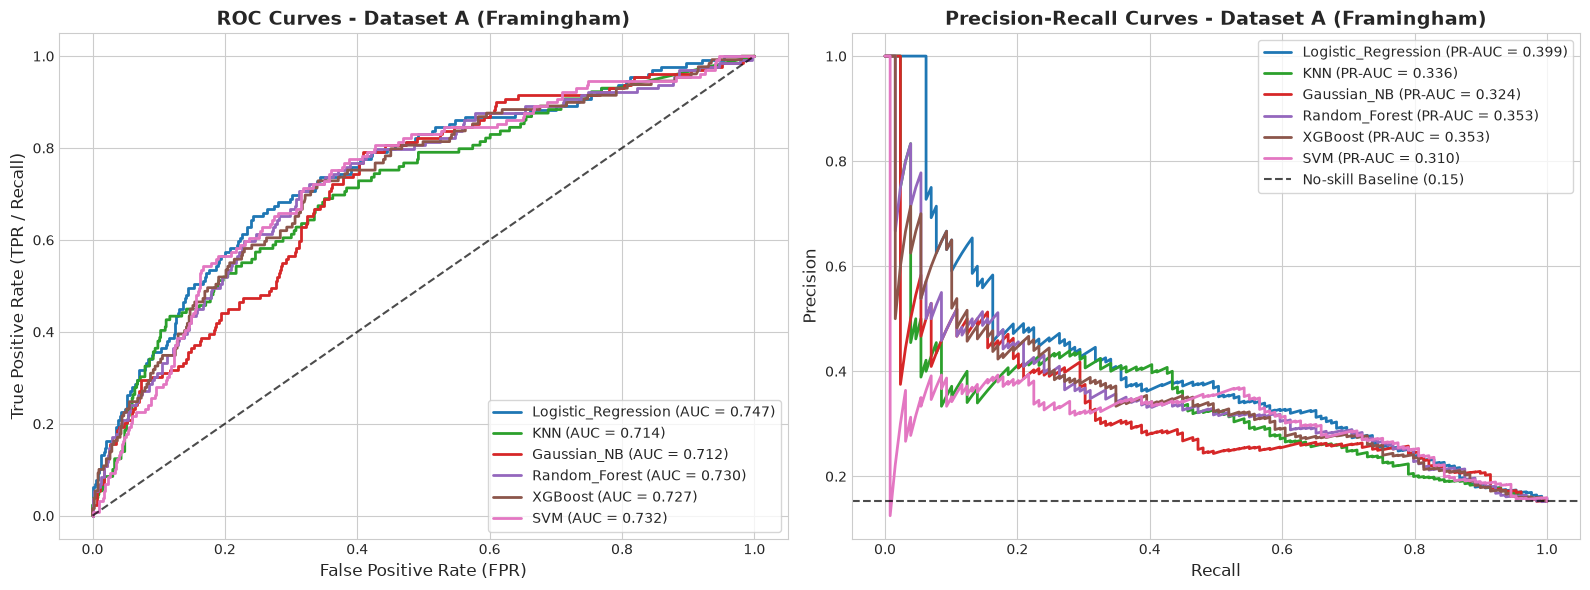

 Saved figure: figures\fig4_roc_pr_curves_cardio.png (DPI=200)


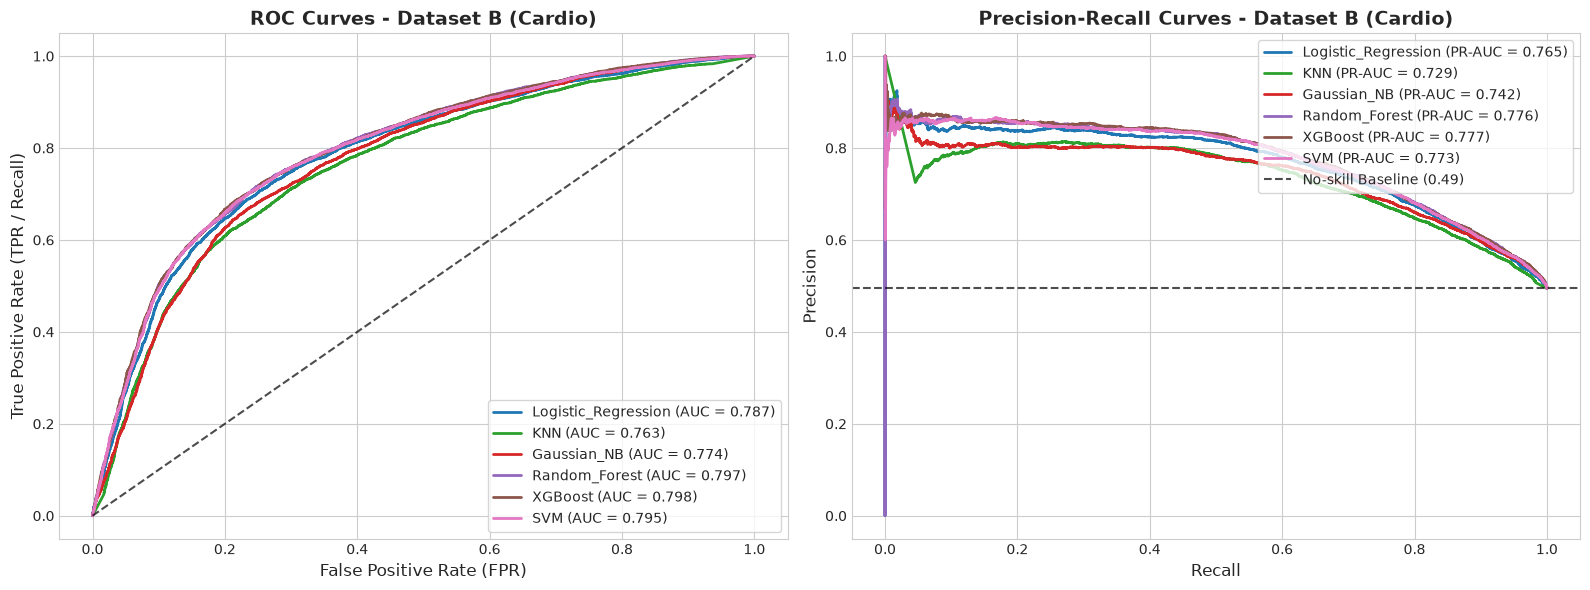

In [8]:
# [In-Domain ROC and PR Curves Visualization]
def plot_curves(y_test, probas_dict, dataset_label, filename):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    colors = [
        "#7f7f7f",
        "#1f77b4",
        "#2ca02c",
        "#d62728",
        "#9467bd",
        "#8c564b",
        "#e377c2",
    ]

    for (name, proba), color in zip(probas_dict.items(), colors):
        if name == "Dummy_Baseline":
            continue
        fpr, tpr, _ = roc_curve(y_test, proba)
        auc = roc_auc_score(y_test, proba)
        ax1.plot(fpr, tpr, lw=2, color=color, label=f"{name} (AUC = {auc:.3f})")

        prec, rec, _ = precision_recall_curve(y_test, proba)
        ap = average_precision_score(y_test, proba)
        ax2.plot(rec, prec, lw=2, color=color, label=f"{name} (PR-AUC = {ap:.3f})")

    ax1.plot([0, 1], [0, 1], "k--", lw=1.5, alpha=0.7)
    ax1.set_title(f"ROC Curves - {dataset_label}", fontsize=14, fontweight="bold")
    ax1.set_xlabel("False Positive Rate (FPR)", fontsize=12)
    ax1.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=12)
    ax1.legend(loc="lower right", frameon=True)

    ax2.axhline(
        y=y_test.mean(),
        color="k",
        linestyle="--",
        lw=1.5,
        alpha=0.7,
        label=f"No-skill Baseline ({y_test.mean():.2f})",
    )
    ax2.set_title(
        f"Precision-Recall Curves - {dataset_label}", fontsize=14, fontweight="bold"
    )
    ax2.set_xlabel("Recall", fontsize=12)
    ax2.set_ylabel("Precision", fontsize=12)
    ax2.legend(loc="upper right", frameon=True)

    plt.tight_layout()
    save_fig(fig, filename)
    plt.show()


plot_curves(
    y_test_A, probas_A, "Dataset A (Framingham)", "fig3_roc_pr_curves_framingham.png"
)
plot_curves(y_test_B, probas_B, "Dataset B (Cardio)", "fig4_roc_pr_curves_cardio.png")


 Saved figure: figures\fig5_learning_curves.png (DPI=200)


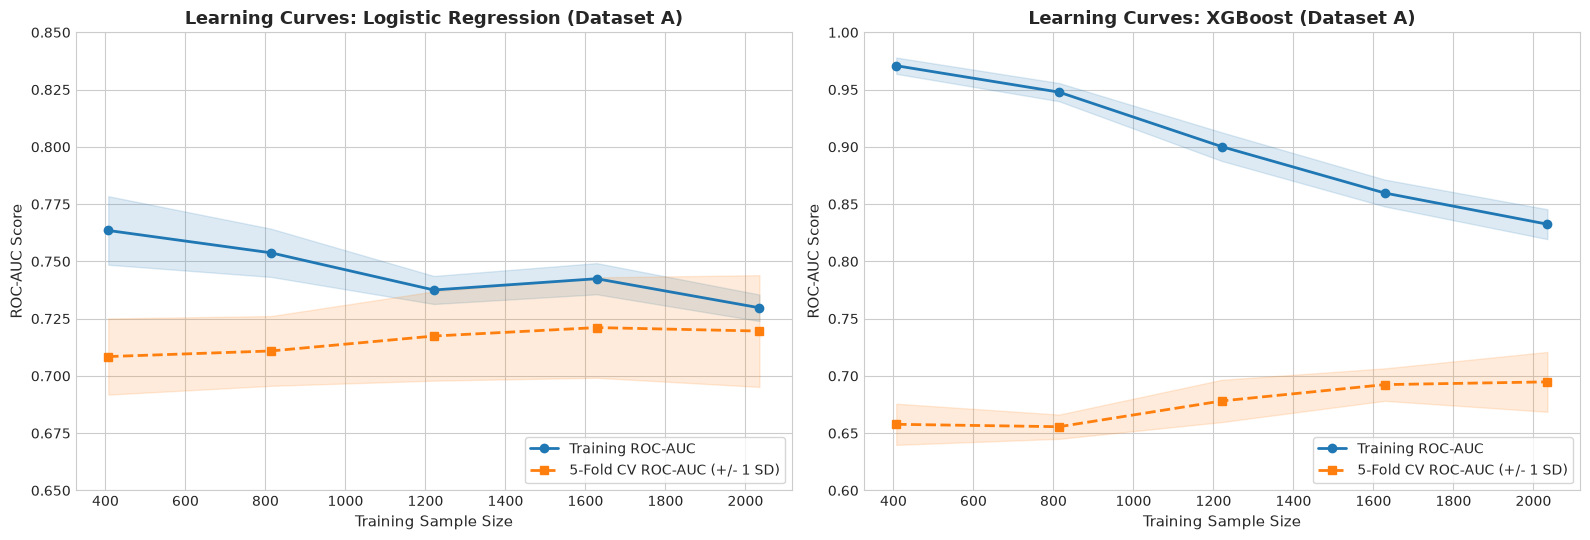

In [ ]:
# [Learning Curves Analysis: Stratified 5-Fold with +/- 1 SD (Model Assessment p. 30)]
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_sizes_grid = np.linspace(0.2, 1.0, 5)

train_sizes, train_scores_lr, val_scores_lr = learning_curve(
    pipes_A["Logistic_Regression"],
    X_train_A,
    y_train_A,
    cv=cv_strat,
    scoring="roc_auc",
    train_sizes=train_sizes_grid,
    n_jobs=-1,
)

train_sizes, train_scores_xgb, val_scores_xgb = learning_curve(
    pipes_A["XGBoost"],
    X_train_A,
    y_train_A,
    cv=cv_strat,
    scoring="roc_auc",
    train_sizes=train_sizes_grid,
    n_jobs=-1,
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))


def plot_learning_subcurve(ax, sizes, tr_scores, val_scores, title, ylim):
    tr_mean, tr_std = np.mean(tr_scores, axis=1), np.std(tr_scores, axis=1)
    val_mean, val_std = np.mean(val_scores, axis=1), np.std(val_scores, axis=1)

    ax.plot(sizes, tr_mean, "o-", color="#1f77b4", lw=2, label="Training ROC-AUC")
    ax.fill_between(
        sizes, tr_mean - tr_std, tr_mean + tr_std, alpha=0.15, color="#1f77b4"
    )

    ax.plot(
        sizes,
        val_mean,
        "s--",
        color="#ff7f0e",
        lw=2,
        label="5-Fold CV ROC-AUC (+/- 1 SD)",
    )
    ax.fill_between(
        sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#ff7f0e"
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Training Sample Size", fontsize=11)
    ax.set_ylabel("ROC-AUC Score", fontsize=11)
    ax.set_ylim(ylim)
    ax.legend(loc="lower right", frameon=True)


plot_learning_subcurve(
    ax1,
    train_sizes,
    train_scores_lr,
    val_scores_lr,
    "Learning Curves: Logistic Regression (Dataset A)",
    [0.65, 0.85],
)
plot_learning_subcurve(
    ax2,
    train_sizes,
    train_scores_xgb,
    val_scores_xgb,
    "Learning Curves: XGBoost (Dataset A)",
    [0.60, 1.00],
)

plt.tight_layout()
save_fig(fig, "fig5_learning_curves.png")
plt.show()


--- SUMMARY TABLE: DATASET A (FRAMINGHAM) ---


,Model,ROC_AUC,AUC_95_CI,PR_AUC,Threshold_Opt,Recall_Opt,Precision_Opt,F1_Opt,Cost_Default(0.5),Cost_Tuned(p*),Cost_Reduction,Brier_Score
1,Logistic_Regression,0.746860,"[0.699, 0.793]",0.399403,0.095509,0.868217,0.212121,0.340944,599.0,501.0,16.4%,0.112594
6,SVM,0.731960,"[0.684, 0.779]",0.309897,0.091480,0.844961,0.204887,0.329803,645.0,523.0,18.9%,0.116944
4,Random_Forest,0.729836,"[0.680, 0.778]",0.353150,0.089929,0.891473,0.194585,0.319444,612.0,546.0,10.8%,0.116220
5,XGBoost,0.727135,"[0.678, 0.772]",0.352897,0.096561,0.875969,0.205829,0.333333,615.0,516.0,16.1%,0.116284
2,KNN,0.713820,"[0.666, 0.768]",0.335714,0.058539,0.875969,0.190556,0.313019,620.0,560.0,9.7%,0.118606
3,Gaussian_NB,0.712046,"[0.662, 0.760]",0.323901,0.050000,0.821705,0.227957,0.356902,524.0,474.0,9.5%,0.151341
0,Dummy_Baseline,0.500000,"[0.500, 0.500]",0.152123,0.500000,0.000000,0.000000,0.000000,645.0,645.0,0.0%,0.152123



--- SUMMARY TABLE: DATASET B (CARDIO) ---


,Model,ROC_AUC,AUC_95_CI,PR_AUC,Threshold_Opt,Recall_Opt,Precision_Opt,F1_Opt,Cost_Default(0.5),Cost_Tuned(p*),Cost_Reduction,Brier_Score
5,XGBoost,0.798064,"[0.790, 0.805]",0.777176,0.378769,0.798498,0.680603,0.734852,12420.0,9384.0,24.4%,0.182095
4,Random_Forest,0.797400,"[0.790, 0.805]",0.776333,0.384045,0.798939,0.682093,0.735907,13159.0,9353.0,28.9%,0.182840
6,SVM,0.795311,"[0.787, 0.803]",0.773450,0.383122,0.796141,0.682277,0.734824,12002.0,9437.0,21.4%,0.183331
1,Logistic_Regression,0.786744,"[0.779, 0.795]",0.764636,0.392863,0.799529,0.676555,0.732919,13147.0,9400.0,28.5%,0.189009
3,Gaussian_NB,0.774016,"[0.766, 0.782]",0.742482,0.184379,0.794521,0.663959,0.723396,14889.0,9705.0,34.8%,0.218226
2,KNN,0.762579,"[0.754, 0.771]",0.728996,0.354802,0.802033,0.646137,0.715694,12627.0,9702.0,23.2%,0.203475
0,Dummy_Baseline,0.500000,"[0.500, 0.500]",0.494681,0.500000,0.000000,0.000000,0.000000,33945.0,33945.0,0.0%,0.494681


 Saved figure: figures\fig6_in_domain_comparison.png (DPI=200)


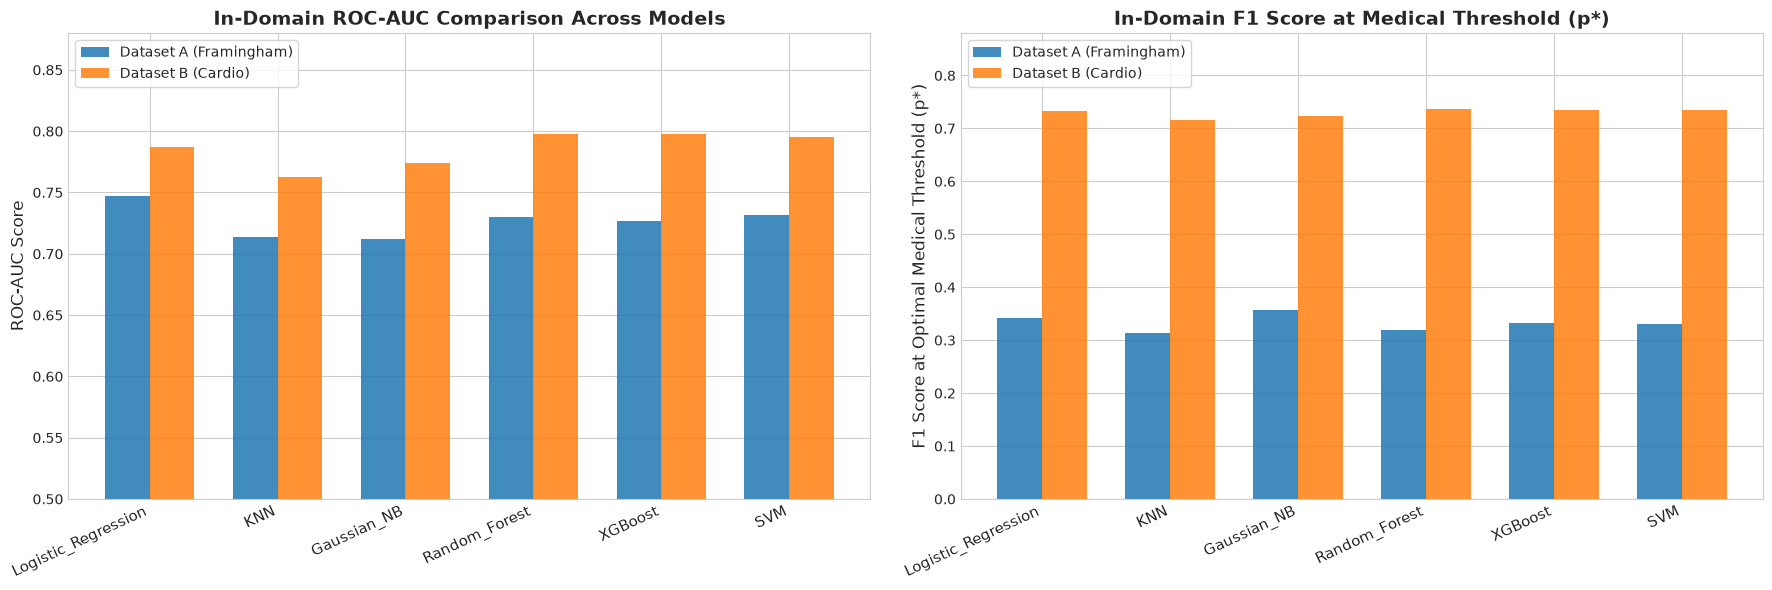

In [10]:
# [In-Domain Results Summary Table & Comparison Plot]
print("--- SUMMARY TABLE: DATASET A (FRAMINGHAM) ---")
display(df_results_A.sort_values(by="ROC_AUC", ascending=False))

print("\n--- SUMMARY TABLE: DATASET B (CARDIO) ---")
display(df_results_B.sort_values(by="ROC_AUC", ascending=False))

# Comparison Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

models_plot = df_results_A[df_results_A["Model"] != "Dummy_Baseline"]["Model"].values
x = np.arange(len(models_plot))
bar_w = 0.35

auc_A = [
    df_results_A[df_results_A["Model"] == m]["ROC_AUC"].values[0] for m in models_plot
]
auc_B = [
    df_results_B[df_results_B["Model"] == m]["ROC_AUC"].values[0] for m in models_plot
]

ax1.bar(
    x - bar_w / 2,
    auc_A,
    bar_w,
    label="Dataset A (Framingham)",
    color="#1f77b4",
    alpha=0.85,
)
ax1.bar(
    x + bar_w / 2, auc_B, bar_w, label="Dataset B (Cardio)", color="#ff7f0e", alpha=0.85
)
ax1.set_xticks(x)
ax1.set_xticklabels(models_plot, rotation=25, ha="right", fontsize=11)
ax1.set_ylabel("ROC-AUC Score", fontsize=12)
ax1.set_ylim([0.5, 0.88])
ax1.set_title(
    "In-Domain ROC-AUC Comparison Across Models", fontsize=14, fontweight="bold"
)
ax1.legend(loc="upper left", frameon=True)

f1_A = [
    df_results_A[df_results_A["Model"] == m]["F1_Opt"].values[0] for m in models_plot
]
f1_B = [
    df_results_B[df_results_B["Model"] == m]["F1_Opt"].values[0] for m in models_plot
]

ax2.bar(
    x - bar_w / 2,
    f1_A,
    bar_w,
    label="Dataset A (Framingham)",
    color="#1f77b4",
    alpha=0.85,
)
ax2.bar(
    x + bar_w / 2, f1_B, bar_w, label="Dataset B (Cardio)", color="#ff7f0e", alpha=0.85
)
ax2.set_xticks(x)
ax2.set_xticklabels(models_plot, rotation=25, ha="right", fontsize=11)
ax2.set_ylabel("F1 Score at Optimal Medical Threshold (p*)", fontsize=12)
ax2.set_ylim([0.0, 0.88])
ax2.set_title(
    "In-Domain F1 Score at Medical Threshold (p*)", fontsize=14, fontweight="bold"
)
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
save_fig(fig, "fig6_in_domain_comparison.png")
plt.show()


## 4. Thực nghiệm Cross-Domain, Phân tích Lỗi & Khắc phục Trôi dữ liệu (Phần Mới - Bonus)

### [Mới - Bonus ML ngoài chương trình giảng dạy]

Khi mô hình đạt hiệu năng cao trên tập nội bộ (_In-Domain_), các kỹ sư thường ngộ nhận mô hình đã sẵn sàng triển khai. Phần thực nghiệm nâng cao này chứng minh hiện tượng suy giảm hiệu năng nghiêm trọng khi chuyển giao xuyên miền và áp dụng 4 kỹ thuật Học Máy hiện đại để kiểm định và giải quyết:

---

### 4.1. Đánh giá Zero-shot Cross-Domain ($A \to B$ và $B \to A$)

- Ta đem mô hình huấn luyện trên Tập A (Framingham, tỷ lệ bệnh ~15%) kiểm thử trực tiếp trên Tập B (Cardio, tỷ lệ bệnh ~50%) và ngược lại.
- **Hiện tượng**: Brier Score tăng vọt, sai lệch dự báo trầm trọng do:
  1. _Covariate Shift_: $P_A(X) \ne P_B(X)$ (Khác biệt về độ tuổi, huyết áp giữa hai quần thể).
  2. _Base-rate / Prior Shift_: $P_A(Y=1) \approx 0.15$ trong khi $P_B(Y=1) \approx 0.50$. Ngưỡng phân loại $p^*$ được tối ưu trên tập nguồn trở nên hoàn toàn sai lệch khi áp dụng sang tập đích!

---

### 4.2. Kiểm định Đối nghịch (Adversarial Validation)

- **Bản chất Học máy**: Gộp toàn bộ dữ liệu $X_A$ và $X_B$, gán nhãn miền: $Y_{\text{domain}} = 1$ nếu mẫu thuộc Tập B, và $0$ nếu thuộc Tập A.
- Huấn luyện mô hình `XGBClassifier` để phân loại nhãn miền này.
- **Ý nghĩa định lượng**:
  - Nếu hai tập dữ liệu đồng nhất (không có trôi dạt): ROC-AUC của mô hình sẽ tiệm cận $0.50$ (mô hình không thể đoán được mẫu đến từ đâu).
  - Nếu ROC-AUC $\gg 0.70$: Chứng minh hai tập dữ liệu trôi phân phối nghiêm trọng.
  - **Feature Importance của bộ phân loại miền**: Chỉ điểm chính xác đặc trưng nào trong lâm sàng bị trôi lệch mạnh nhất giữa hai quốc gia/quần thể.

---

### 4.3. Hiệu chuẩn Xác suất Hậu nghiệm Hai chiều (Bidirectional Post-hoc Probability Calibration)

- Áp dụng `CalibratedClassifierCV` (Platt Scaling và Isotonic Regression) trên lát cắt Validation nhỏ của miền đích cho **cả hai chiều chuyển giao ($A \to B$ và $B \to A$)**.
- Khắc phục đồng thời hiện tượng dự báo quá thấp (_Under-confidence_ khi chuyển $15\% \to 50\%$) lẫn dự báo quá cao (_Over-confidence_ khi chuyển $50\% \to 15\%$) mà không cần huấn luyện lại mô hình nguồn.
- Vẽ đường cong tin cậy đối xứng (_Reliability Diagrams_) và định lượng mức giảm sai số qua Brier Score.

---

### 4.4. Khám phá Cơ chế Ra Quyết định & Phân tích Âm tính giả với SHAP

- Sử dụng `shap.TreeExplainer` cho mô hình XGBoost trên cả hai tập dữ liệu.
- So sánh xếp hạng tầm quan trọng đặc trưng toàn cục (_Global Feature Importance_) giữa 2 miền: Yếu tố nào quyết định nguy cơ tim mạch ở Mỹ (Tập A) so với Đông Âu (Tập B)?
- **Phân tích Cục bộ Trường hợp Bỏ sót Bệnh (False Negative Case Study)**: Trực quan hóa thác giá trị SHAP (_Waterfall Plot_) trên các bệnh nhân thực tế có biến cố tim mạch nhưng bị mô hình dự đoán xác suất thấp, tìm ra nguyên nhân lâm sàng dẫn đến nhận định sai lầm của mô hình.

---

### 4.5. Dự đoán Phù hợp Đảm bảo Độ phủ (Conformal Prediction via MAPIE)

- Trong chẩn đoán y tế, một dự đoán nhị phân cứng $(0$ hoặc $1)$ có thể gây nguy hiểm khi mô hình nằm trong vùng biên không chắc chắn (_Epistemic Uncertainty_).
- Áp dụng **Conformal Prediction** thông qua thư viện `MAPIE`, thiết lập mức ý nghĩa thống kê $\alpha = 0.10$ để đạt bảo chứng toán học:
  $$P(Y \in C(X)) \ge 1 - \alpha = 90\%$$
- Đầu ra của mô hình là một tập dự đoán:
  - $\{0\}$: Chắc chắn khỏe mạnh.
  - $\{1\}$: Chắc chắn nguy cơ cao (cần can thiệp).
  - $\{0, 1\}$: **Bất định (Uncertain)** $\to$ Tự động gắn cờ chuyển hồ sơ bệnh nhân cho Bác sĩ chuyên khoa hội chẩn trực tiếp!


In [11]:
# [4.1. Zero-shot Cross-Domain Transfer Evaluation]
cross_results = []


def eval_cross_domain(
    model_name, pipe_src, X_tgt, y_tgt, src_name, tgt_name, thresh_src
):
    tgt_proba = pipe_src.predict_proba(X_tgt)[:, 1]
    tgt_pred_def = (tgt_proba >= 0.50).astype(int)
    tgt_pred_src_thresh = (tgt_proba >= thresh_src).astype(int)

    auc = roc_auc_score(y_tgt, tgt_proba)
    ap = average_precision_score(y_tgt, tgt_proba)
    rec_def = recall_score(y_tgt, tgt_pred_def)
    rec_thresh = recall_score(y_tgt, tgt_pred_src_thresh)
    cost_def = compute_medical_cost(y_tgt, tgt_pred_def)
    cost_thresh = compute_medical_cost(y_tgt, tgt_pred_src_thresh)
    brier = brier_score_loss(y_tgt, tgt_proba)

    return {
        "Transfer": f"{src_name} -> {tgt_name}",
        "Model": model_name,
        "Cross_ROC_AUC": auc,
        "Cross_PR_AUC": ap,
        "Recall@0.5": rec_def,
        "Recall@Src_Thresh": rec_thresh,
        "Cost@0.5": cost_def,
        "Cost@Src_Thresh": cost_thresh,
        "Brier_Score": brier,
    }


for m in ["Logistic_Regression", "Random_Forest", "XGBoost"]:
    # Model A tested on Test B
    res_A2B = eval_cross_domain(
        m, pipes_A[m], X_test_B, y_test_B, "Dataset A", "Dataset B", thresh_A[m]
    )
    cross_results.append(res_A2B)

    # Model B tested on Test A
    res_B2A = eval_cross_domain(
        m, pipes_B[m], X_test_A, y_test_A, "Dataset B", "Dataset A", thresh_B[m]
    )
    cross_results.append(res_B2A)

df_cross = pd.DataFrame(cross_results)
print("--- ZERO-SHOT CROSS-DOMAIN EVALUATION RESULTS ---")
display(df_cross)


--- ZERO-SHOT CROSS-DOMAIN EVALUATION RESULTS ---


,Transfer,Model,Cross_ROC_AUC,Cross_PR_AUC,Recall@0.5,Recall@Src_Thresh,Cost@0.5,Cost@Src_Thresh,Brier_Score
0,Dataset A -> Dataset B,Logistic_Regression,0.714767,0.681195,0.005450,0.773457,33768.0,10920.0,0.357439
1,Dataset B -> Dataset A,Logistic_Regression,0.696704,0.306957,0.798450,0.875969,510.0,544.0,0.334164
2,Dataset A -> Dataset B,Random_Forest,0.723816,0.682470,0.007070,0.839593,33733.0,9311.0,0.349415
3,Dataset B -> Dataset A,Random_Forest,0.659626,0.240305,0.790698,0.875969,559.0,573.0,0.327785
4,Dataset A -> Dataset B,XGBoost,0.720280,0.679683,0.015466,0.848137,33498.0,9114.0,0.346953
5,Dataset B -> Dataset A,XGBoost,0.668494,0.263631,0.775194,0.837209,546.0,582.0,0.329775



**************************************************
ADVERSARIAL VALIDATION ROC-AUC: 0.9841
CONCLUSION: Severe distribution shift detected between Dataset A (Framingham) and Dataset B (Cardio)!
**************************************************

Top Drift Features (Gain Importance):
  1. chol_level  : 0.4763
  2. smoker      : 0.1143
  3. dia_bp      : 0.1014
  4. gluc_level  : 0.0963
  5. age         : 0.0656
  6. sys_bp      : 0.0532
  7. is_male     : 0.0487
  8. bmi         : 0.0441


 Saved figure: figures\fig7_adversarial_validation_drift.png (DPI=200)


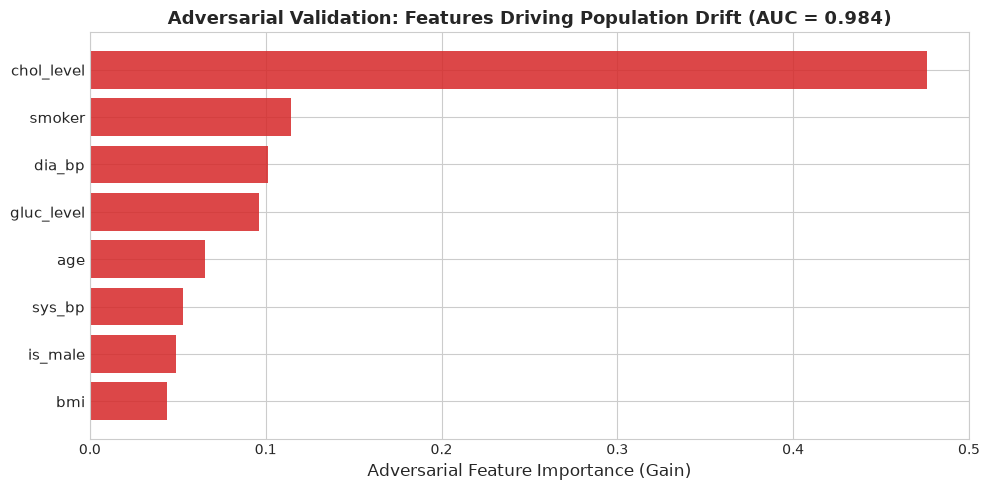

In [12]:
# [4.2. Adversarial Validation: Quantifying Data Drift (Leakage-Free)]
# Prepare balanced combined dataset with domain target (0 = Dataset A, 1 = Dataset B)
X_adv_A = X_train_A.copy()
X_adv_B = X_train_B.sample(n=len(X_train_A), random_state=42).copy()

X_adv = pd.concat([X_adv_A, X_adv_B], axis=0).reset_index(drop=True)
y_domain = np.array([0] * len(X_adv_A) + [1] * len(X_adv_B))

# Split BEFORE preprocessing to prevent data leakage into test fold
X_adv_tr, X_adv_te, y_adv_tr, y_adv_te = train_test_split(
    X_adv, y_domain, test_size=0.33, stratify=y_domain, random_state=42
)

adv_pipe = Pipeline(
    [
        ("preprocessor", make_preprocessor()),
        (
            "classifier",
            XGBClassifier(
                n_estimators=100,
                max_depth=3,
                learning_rate=0.05,
                eval_metric="logloss",
                random_state=42,
            ),
        ),
    ]
)
adv_pipe.fit(X_adv_tr, y_adv_tr)

adv_probs = adv_pipe.predict_proba(X_adv_te)[:, 1]
adv_auc = roc_auc_score(y_adv_te, adv_probs)

print(f"\n{'*' * 50}")
print(f"ADVERSARIAL VALIDATION ROC-AUC: {adv_auc:.4f}")
if adv_auc > 0.70:
    print(
        "CONCLUSION: Severe distribution shift detected between Dataset A (Framingham) and Dataset B (Cardio)!"
    )
else:
    print("CONCLUSION: Distributions are relatively homogenous.")
print(f"{'*' * 50}\n")

# Rank the most shifting features directly from fitted preprocessor feature names
feat_names = adv_pipe.named_steps["preprocessor"].get_feature_names_out().tolist()
importances = adv_pipe.named_steps["classifier"].feature_importances_
indices = np.argsort(importances)[::-1]

print("Top Drift Features (Gain Importance):")
for rank, idx in enumerate(indices, 1):
    print(f"  {rank}. {feat_names[idx]:12s}: {importances[idx]:.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(range(len(feat_names)), importances[indices[::-1]], color="#d62728", alpha=0.85)
ax.set_yticks(range(len(feat_names)))
ax.set_yticklabels([feat_names[i] for i in indices[::-1]], fontsize=11)
ax.set_xlabel("Adversarial Feature Importance (Gain)", fontsize=12)
ax.set_title(
    f"Adversarial Validation: Features Driving Population Drift (AUC = {adv_auc:.3f})",
    fontsize=13,
    fontweight="bold",
)

plt.tight_layout()
save_fig(fig, "fig7_adversarial_validation_drift.png")
plt.show()


--- BIDIRECTIONAL BRIER SCORE BEFORE & AFTER CALIBRATION ---
Transfer A -> B | Raw: 0.3470 | Sigmoid: 0.2195 (-36.7%) | Isotonic: 0.2123 (-38.8%)
Transfer B -> A | Raw: 0.3298 | Sigmoid: 0.1235 (-62.5%) | Isotonic: 0.1254 (-62.0%)


 Saved figure: figures\fig8_calibration_curves.png (DPI=200)


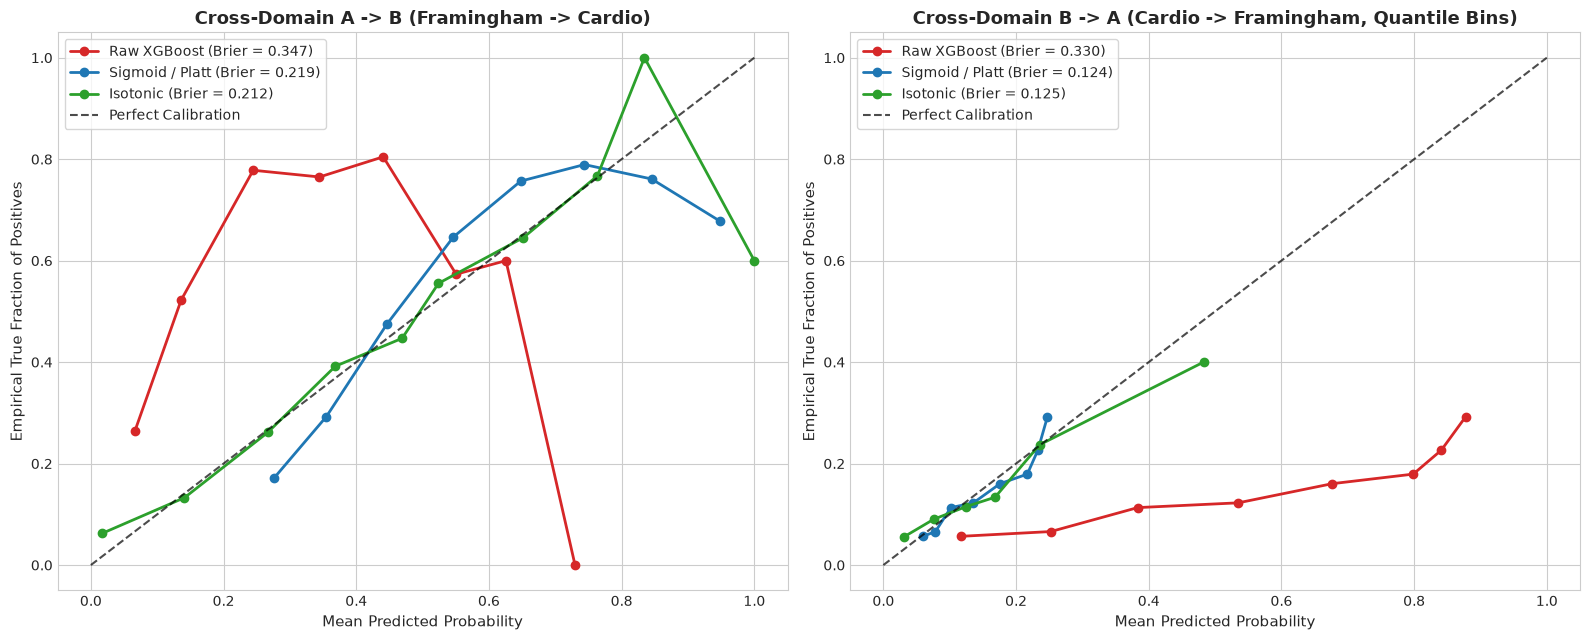

In [ ]:
# [4.3. Bidirectional Post-hoc Probability Calibration: A -> B and B -> A]
def fit_calibrators(pipe_src, X_val_tgt, y_val_tgt):
    if FrozenEstimator is not None:
        c_iso = CalibratedClassifierCV(
            estimator=FrozenEstimator(pipe_src), method="isotonic"
        )
        c_sig = CalibratedClassifierCV(
            estimator=FrozenEstimator(pipe_src), method="sigmoid"
        )
    else:
        c_iso = CalibratedClassifierCV(
            estimator=pipe_src, method="isotonic", cv="prefit"
        )
        c_sig = CalibratedClassifierCV(
            estimator=pipe_src, method="sigmoid", cv="prefit"
        )
    c_iso.fit(X_val_tgt, y_val_tgt)
    c_sig.fit(X_val_tgt, y_val_tgt)
    return c_iso, c_sig


# Direction 1: A -> B (15.2% -> 49.5%, Under-confident repair)
pipe_A_xgb = pipes_A["XGBoost"]
cal_iso_A2B, cal_sig_A2B = fit_calibrators(pipe_A_xgb, X_val_B, y_val_B)
p_raw_A2B = pipe_A_xgb.predict_proba(X_test_B)[:, 1]
p_sig_A2B = cal_sig_A2B.predict_proba(X_test_B)[:, 1]
p_iso_A2B = cal_iso_A2B.predict_proba(X_test_B)[:, 1]

# Direction 2: B -> A (49.5% -> 15.2%, Over-confident repair)
pipe_B_xgb = pipes_B["XGBoost"]
cal_iso_B2A, cal_sig_B2A = fit_calibrators(pipe_B_xgb, X_val_A, y_val_A)
p_raw_B2A = pipe_B_xgb.predict_proba(X_test_A)[:, 1]
p_sig_B2A = cal_sig_B2A.predict_proba(X_test_A)[:, 1]
p_iso_B2A = cal_iso_B2A.predict_proba(X_test_A)[:, 1]

b_raw_ab = brier_score_loss(y_test_B, p_raw_A2B)
b_sig_ab = brier_score_loss(y_test_B, p_sig_A2B)
b_iso_ab = brier_score_loss(y_test_B, p_iso_A2B)

b_raw_ba = brier_score_loss(y_test_A, p_raw_B2A)
b_sig_ba = brier_score_loss(y_test_A, p_sig_B2A)
b_iso_ba = brier_score_loss(y_test_A, p_iso_B2A)

print("--- BIDIRECTIONAL BRIER SCORE BEFORE & AFTER CALIBRATION ---")
print(
    f"Transfer A -> B | Raw: {b_raw_ab:.4f} | "
    f"Sigmoid: {b_sig_ab:.4f} (-{(b_raw_ab - b_sig_ab) / b_raw_ab * 100:.1f}%) | "
    f"Isotonic: {b_iso_ab:.4f} (-{(b_raw_ab - b_iso_ab) / b_raw_ab * 100:.1f}%)"
)
print(
    f"Transfer B -> A | Raw: {b_raw_ba:.4f} | "
    f"Sigmoid: {b_sig_ba:.4f} (-{(b_raw_ba - b_sig_ba) / b_raw_ba * 100:.1f}%) | "
    f"Isotonic: {b_iso_ba:.4f} (-{(b_raw_ba - b_iso_ba) / b_raw_ba * 100:.1f}%)"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))


def plot_rel_curve(
    ax, y_true, p_raw, p_sig, p_iso, title, n_bins=10, strategy="uniform"
):
    for p, label, col in zip(
        [p_raw, p_sig, p_iso],
        ["Raw XGBoost", "Sigmoid / Platt", "Isotonic"],
        ["#d62728", "#1f77b4", "#2ca02c"],
    ):
        prob_true, prob_pred = calibration_curve(
            y_true, p, n_bins=n_bins, strategy=strategy
        )
        brier = brier_score_loss(y_true, p)
        ax.plot(
            prob_pred,
            prob_true,
            marker="o",
            lw=2,
            color=col,
            label=f"{label} (Brier = {brier:.3f})",
        )
    ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration", alpha=0.7)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Mean Predicted Probability", fontsize=11)
    ax.set_ylabel("Empirical True Fraction of Positives", fontsize=11)
    ax.legend(loc="upper left", frameon=True)


plot_rel_curve(
    ax1,
    y_test_B,
    p_raw_A2B,
    p_sig_A2B,
    p_iso_A2B,
    "Cross-Domain A -> B (Framingham -> Cardio)",
    n_bins=10,
    strategy="uniform",
)
plot_rel_curve(
    ax2,
    y_test_A,
    p_raw_B2A,
    p_sig_B2A,
    p_iso_B2A,
    "Cross-Domain B -> A (Cardio -> Framingham, Quantile Bins)",
    n_bins=8,
    strategy="quantile",
)

plt.tight_layout()
save_fig(fig, "fig8_calibration_curves.png")
plt.show()


--- MULTI-DOMAIN MEAN |SHAP| FEATURE IMPORTANCE ---


,Feature,Dataset A (Framingham - US),Dataset B (Cardio - Eastern Europe)
0,age,0.570923,0.257239
2,sys_bp,0.262290,0.826762
6,is_male,0.185711,0.005477
7,smoker,0.118691,0.027449
3,dia_bp,0.094431,0.095519
1,bmi,0.085832,0.100789
5,gluc_level,0.038109,0.027188
4,chol_level,0.025475,0.195595


 Saved figure: figures\fig9_shap_global_summary.png (DPI=200)


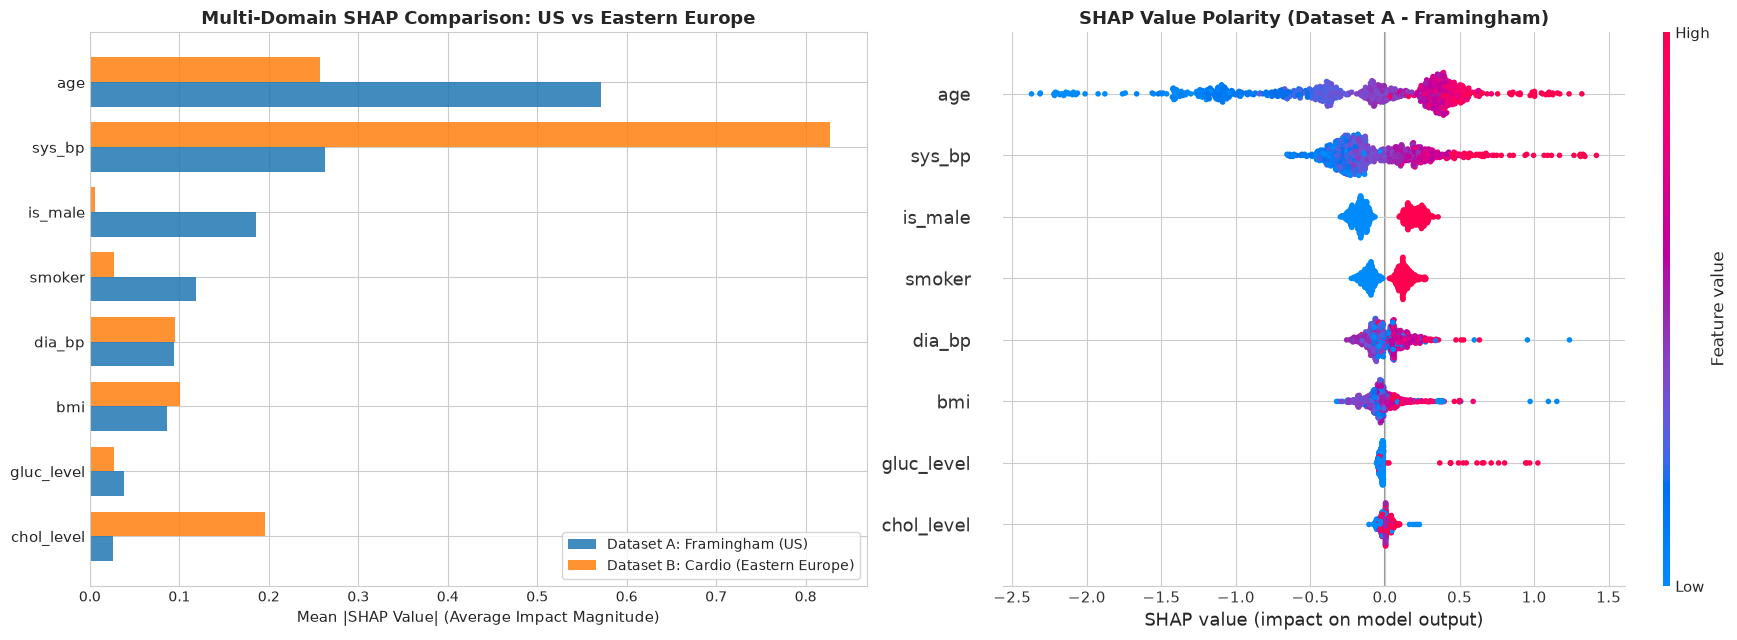

Total False Negatives on Test A: 16 patients out of 129 actual positive cases.
Analyzing Worst False Negative Patient (Index #672):
Predicted Probability: 0.017 vs True Label: 1
Patient Profile: Age=35.0, BP=112.0/62.5, BMI=21.03, Male=1, Smoker=1, Chol=1, Gluc=1


 Saved figure: figures\fig10_shap_local_false_negatives.png (DPI=200)


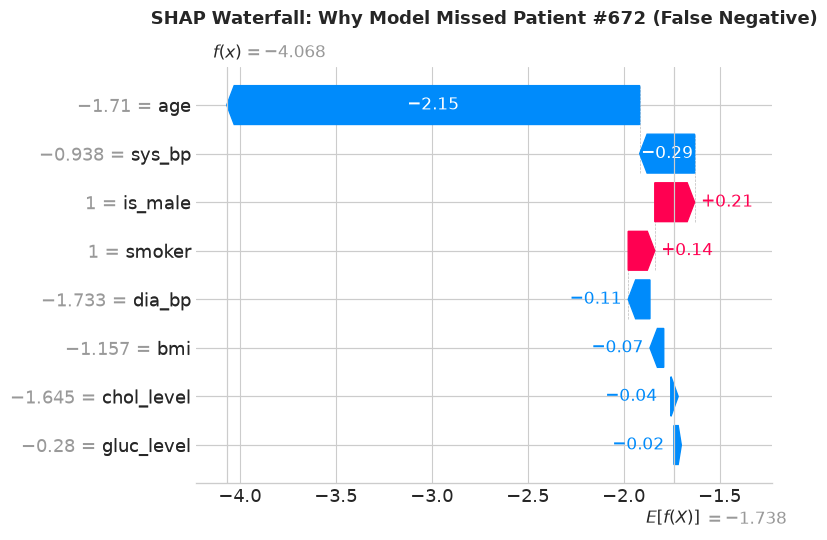

In [ ]:
# [4.4. Multi-Domain SHAP Global Comparison (US vs Eastern Europe) & False Negative Case Study]
# 1. Extract SHAP for Dataset A (Framingham - US)
preproc_A_xgb = pipes_A["XGBoost"].named_steps["preprocessor"]
xgb_clf_A = pipes_A["XGBoost"].named_steps["classifier"]
X_test_A_trans = preproc_A_xgb.transform(X_test_A)
shap_cols_A = preproc_A_xgb.get_feature_names_out().tolist()

explainer_A = shap.TreeExplainer(xgb_clf_A)
shap_explanation_A = explainer_A(X_test_A_trans)

# 2. Extract SHAP for Dataset B (Cardio - Eastern Europe) on N=2000 test subsample
preproc_B_xgb = pipes_B["XGBoost"].named_steps["preprocessor"]
xgb_clf_B = pipes_B["XGBoost"].named_steps["classifier"]
X_sample_B = X_test_B.sample(n=2000, random_state=42)
X_test_B_trans = preproc_B_xgb.transform(X_sample_B)
shap_cols_B = preproc_B_xgb.get_feature_names_out().tolist()

explainer_B = shap.TreeExplainer(xgb_clf_B)
shap_explanation_B = explainer_B(X_test_B_trans)

# Align mean |SHAP| safely by feature name
mean_shap_A = dict(zip(shap_cols_A, np.mean(np.abs(shap_explanation_A.values), axis=0)))
mean_shap_B = dict(zip(shap_cols_B, np.mean(np.abs(shap_explanation_B.values), axis=0)))

df_shap_cmp = pd.DataFrame(
    {
        "Feature": shap_cols_A,
        "Dataset A (Framingham - US)": [mean_shap_A[f] for f in shap_cols_A],
        "Dataset B (Cardio - Eastern Europe)": [mean_shap_B[f] for f in shap_cols_A],
    }
).sort_values(by="Dataset A (Framingham - US)", ascending=True)

print("--- MULTI-DOMAIN MEAN |SHAP| FEATURE IMPORTANCE ---")
display(df_shap_cmp.sort_values(by="Dataset A (Framingham - US)", ascending=False))

# 3. 2-Panel Plot: Left = Cross-population Mean |SHAP| Comparison, Right = Dataset A Beeswarm
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))
y_idx = np.arange(len(df_shap_cmp))
bar_h = 0.38

ax1.barh(
    y_idx - bar_h / 2,
    df_shap_cmp["Dataset A (Framingham - US)"],
    bar_h,
    label="Dataset A: Framingham (US)",
    color="#1f77b4",
    alpha=0.85,
)
ax1.barh(
    y_idx + bar_h / 2,
    df_shap_cmp["Dataset B (Cardio - Eastern Europe)"],
    bar_h,
    label="Dataset B: Cardio (Eastern Europe)",
    color="#ff7f0e",
    alpha=0.85,
)
ax1.set_yticks(y_idx)
ax1.set_yticklabels(df_shap_cmp["Feature"], fontsize=11)
ax1.set_xlabel("Mean |SHAP Value| (Average Impact Magnitude)", fontsize=11)
ax1.set_title(
    "Multi-Domain SHAP Comparison: US vs Eastern Europe", fontsize=13, fontweight="bold"
)
ax1.legend(loc="lower right", frameon=True)

plt.sca(ax2)
shap.summary_plot(
    shap_explanation_A.values,
    X_test_A_trans,
    feature_names=shap_cols_A,
    show=False,
    plot_size=None,
)
ax2.set_title(
    "SHAP Value Polarity (Dataset A - Framingham)", fontsize=13, fontweight="bold"
)

plt.tight_layout()
save_fig(fig, "fig9_shap_global_summary.png")
plt.show()

# 4. False Negative Case Analysis: Find high-risk patients missed by the model at p*
y_pred_A_opt = (probas_A["XGBoost"] >= thresh_A["XGBoost"]).astype(int)
fn_indices = np.where((y_test_A.values == 1) & (y_pred_A_opt == 0))[0]

print(
    f"Total False Negatives on Test A: {len(fn_indices)} patients out of {y_test_A.sum()} actual positive cases."
)

if len(fn_indices) > 0:
    worst_fn_idx = fn_indices[np.argmin(probas_A["XGBoost"][fn_indices])]
    print(f"Analyzing Worst False Negative Patient (Index #{worst_fn_idx}):")
    print(
        f"Predicted Probability: {probas_A['XGBoost'][worst_fn_idx]:.3f} vs True Label: 1"
    )

    fn_patient_raw = X_test_A.iloc[worst_fn_idx]
    print(
        f"Patient Profile: Age={fn_patient_raw['age']}, BP={fn_patient_raw['sys_bp']}/{fn_patient_raw['dia_bp']}, "
        f"BMI={fn_patient_raw['bmi']}, Male={int(fn_patient_raw['is_male'])}, "
        f"Smoker={int(fn_patient_raw['smoker'])}, Chol={int(fn_patient_raw['chol_level'])}, Gluc={int(fn_patient_raw['gluc_level'])}"
    )

    fig = plt.figure(figsize=(10, 6))
    shap_exp_sample = shap_explanation_A[worst_fn_idx]
    shap_exp_sample.feature_names = shap_cols_A
    shap.plots.waterfall(shap_exp_sample, show=False)
    plt.title(
        f"SHAP Waterfall: Why Model Missed Patient #{worst_fn_idx} (False Negative)",
        fontsize=13,
        fontweight="bold",
        pad=15,
    )
    plt.tight_layout()
    save_fig(plt.gcf(), "fig10_shap_local_false_negatives.png")
    plt.show()



--- CONFORMAL PREDICTION (MAPIE) ON Dataset A (Framingham) ---
Target Coverage (1 - alpha): 90.0% | Empirical Coverage: 90.4%
  - Low Risk Only {0}:     83.37% (Safe to discharge)
  - High Risk Only {1}:     0.00% (Definite intervention)
  - Uncertain {0, 1}:      16.63% (FLAG FOR DOCTOR CONSULTATION)
  - Empty Sets {}:          0.00%



--- CONFORMAL PREDICTION (MAPIE) ON Dataset B (Cardio) ---
Target Coverage (1 - alpha): 90.0% | Empirical Coverage: 90.1%
  - Low Risk Only {0}:     27.08% (Safe to discharge)
  - High Risk Only {1}:    29.07% (Definite intervention)
  - Uncertain {0, 1}:      43.85% (FLAG FOR DOCTOR CONSULTATION)
  - Empty Sets {}:          0.00%


 Saved figure: figures\fig11_conformal_prediction_coverage.png (DPI=200)


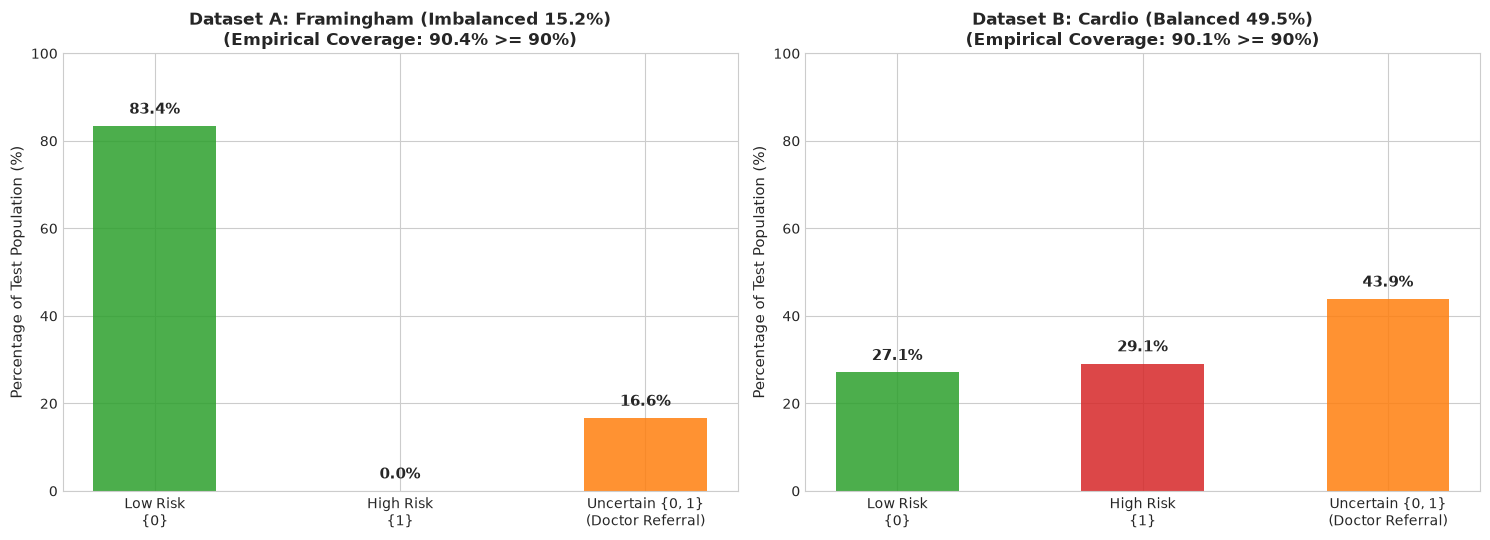

In [15]:
# [4.5. Conformal Prediction via MAPIE: Trustworthy Screening (Dataset A & Dataset B)]
ALPHA = 0.10  # 90% guaranteed coverage


def run_conformal_eval(pipe_model, X_cal, y_cal, X_test, y_test, dataset_label):
    try:
        mapie_clf = SplitConformalClassifier(
            estimator=pipe_model, confidence_level=1.0 - ALPHA, prefit=True
        )
        mapie_clf.conformalize(X_cal, y_cal)
        _, y_ps = mapie_clf.predict_set(X_test)
    except Exception:
        from mapie.classification import MapieClassifier

        mapie_clf = MapieClassifier(estimator=pipe_model, method="lac", cv="prefit")
        mapie_clf.fit(X_cal, y_cal)
        _, y_ps = mapie_clf.predict(X_test, alpha=ALPHA)

    set_sizes = y_ps[:, :, 0].sum(axis=1)
    covered = [y_ps[i, y_test.iloc[i], 0] for i in range(len(y_test))]
    emp_cov = float(np.mean(covered))

    p0 = float(np.mean((y_ps[:, 0, 0] == 1) & (y_ps[:, 1, 0] == 0)))
    p1 = float(np.mean((y_ps[:, 0, 0] == 0) & (y_ps[:, 1, 0] == 1)))
    p01 = float(np.mean((y_ps[:, 0, 0] == 1) & (y_ps[:, 1, 0] == 1)))
    p_empty = float(np.mean(set_sizes == 0))

    print(f"\n--- CONFORMAL PREDICTION (MAPIE) ON {dataset_label} ---")
    print(
        f"Target Coverage (1 - alpha): {1 - ALPHA:.1%} | Empirical Coverage: {emp_cov:.1%}"
    )
    print(f"  - Low Risk Only {{0}}:    {p0 * 100:6.2f}% (Safe to discharge)")
    print(f"  - High Risk Only {{1}}:   {p1 * 100:6.2f}% (Definite intervention)")
    print(
        f"  - Uncertain {{0, 1}}:     {p01 * 100:6.2f}% (FLAG FOR DOCTOR CONSULTATION)"
    )
    print(f"  - Empty Sets {{}}:        {p_empty * 100:6.2f}%")

    return emp_cov, [p0 * 100, p1 * 100, p01 * 100]


cov_A, pcts_A = run_conformal_eval(
    pipes_A["Random_Forest"],
    X_val_A,
    y_val_A,
    X_test_A,
    y_test_A,
    "Dataset A (Framingham)",
)
cov_B, pcts_B = run_conformal_eval(
    pipes_B["Random_Forest"], X_val_B, y_val_B, X_test_B, y_test_B, "Dataset B (Cardio)"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
categories = ["Low Risk\n{0}", "High Risk\n{1}", "Uncertain {0, 1}\n(Doctor Referral)"]
colors = ["#2ca02c", "#d62728", "#ff7f0e"]

for ax, pcts, cov, title in zip(
    [ax1, ax2],
    [pcts_A, pcts_B],
    [cov_A, cov_B],
    ["Dataset A: Framingham (Imbalanced 15.2%)", "Dataset B: Cardio (Balanced 49.5%)"],
):
    bars = ax.bar(categories, pcts, color=colors, alpha=0.85, width=0.5)
    ax.set_ylabel("Percentage of Test Population (%)", fontsize=11)
    ax.set_ylim([0, 100])
    ax.set_title(
        f"{title}\n(Empirical Coverage: {cov * 100:.1f}% >= 90%)",
        fontsize=12,
        fontweight="bold",
    )
    for bar in bars:
        yval = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            yval + 2,
            f"{yval:.1f}%",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
        )

plt.tight_layout()
save_fig(fig, "fig11_conformal_prediction_coverage.png")
plt.show()


## 5. Kết luận, Bàn luận & Khuyến nghị Triển khai

### [Tổng hợp toàn bộ nghiên cứu]

---

### 1. Tổng kết Kết quả Nghiên cứu Thực nghiệm

1. **Hiệu năng Mô hình In-Domain (Nội miền)**:
   - Trên Tập A (Framingham, mất cân bằng 15.19%): **Logistic Regression** đạt ROC-AUC cao nhất (**0.747** [0.699, 0.793], PR-AUC **0.399**, Brier **0.113**), theo sát là **SVM RBF** (**0.732**), **Random Forest** (**0.730**) và **XGBoost** (**0.727**). Chuẩn hóa biến thứ bậc (`chol_level`, `gluc_level`) giúp `KNN` cải thiện mức giảm chi phí lên **9.7%** (Cost 620 $\to$ 560).
   - Trên Tập B (Cardio, quy mô 68.619 mẫu sạch): Các mô hình tổ hợp cây **XGBoost** (**0.798** [0.790, 0.805]) và **Random Forest** (**0.797** [0.790, 0.805]) dẫn đầu, trong khi **Nystroem + SGD** (**0.795**) giải quyết triệt để nút thắt $O(N^3)$ của Kernel SVM.
   - **Tối ưu hóa ngưỡng quyết định y tế ($p^*$)**: Giữ nguyên xác suất hậu nghiệm chuẩn rồi tối ưu ngưỡng theo $\text{Recall} \ge 0.80$ giúp giảm **9.5% đến 18.9%** tổng chi phí y tế trên Tập A và **21.4% đến 34.8%** trên Tập B.

2. **Bài học Sống còn về Đánh giá Xuyên miền (Cross-Domain Shift)**:
   - Khi đưa mô hình Tập A dự báo trực tiếp sang Tập B ($A \to B$) tại ngưỡng mặc định $p=0.50$, Recall sụt thảm hại xuống chỉ còn **0.55% – 1.55%** và Brier Score vọt lên **0.347**.
   - **Adversarial Validation** (tách tập kiểm tra trước khi fit preprocessor để chống rò rỉ) đạt **ROC-AUC = 0.9841**, chỉ điểm các đặc trưng trôi phân phối mạnh nhất giữa Mỹ và Đông Âu: `chol_level` (0.4763), `smoker` (0.1143), `dia_bp` (0.1014) và `gluc_level` (0.0963).
   - **Hiệu chuẩn Xác suất Hậu nghiệm Hai chiều (Platt / Isotonic)** phục hồi chuẩn xác suất cho cả hai hướng trôi lệch:
     - Chiều $A \to B$ (khắc phục _Under-confidence_): Hạ Brier Score từ **0.3470 xuống 0.2123** (**giảm 38.8%** với Isotonic).
     - Chiều $B \to A$ (khắc phục _Over-confidence_): Hạ Brier Score từ **0.3298 xuống 0.1235** (**giảm 62.5%** với Sigmoid/Platt).

3. **Tính Minh bạch & Đảm bảo An toàn Y tế (Trustworthy AI)**:
   - **SHAP Đa miền (Mỹ vs Đông Âu)**: Bóc tách sự khác biệt dịch tễ học rõ nét: trên Tập A (dự báo biến cố 10 năm), `age` (`0.571`) và `sys_bp` (`0.262`) chi phối mạnh nhất; trong khi trên Tập B (chẩn đoán hiện diện bệnh), `sys_bp` (`0.827`) áp đảo và `chol_level` (`0.196`) có sức nặng cao gấp gần 8 lần so với Tập A (`0.025`).
   - **SHAP Waterfall ca Âm tính giả #672**: Giải mã ca bệnh 35 tuổi, nam, hút thuốc, huyết áp 112/62.5 mmHg bị đánh giá nguy cơ thấp ($p=0.017$) do tuổi trẻ kéo mạnh giá trị SHAP về miền âm (`-2.15`), lấn át yếu tố hút thuốc (`+0.14`) và giới tính nam (`+0.21`).
   - **Conformal Prediction (MAPIE, $\alpha = 0.10$)**: Đảm bảo độ phủ thực nghiệm vượt cam kết **90%** (**90.4%** trên Framingham và **90.1%** trên Cardio). Trên Tập A lệch lớp, hệ thống khoanh vùng **16.63%** ca bất định $\{0, 1\}$ cho bác sĩ hội chẩn và loại trừ an toàn **83.37%** ca $\{0\}$; trên Tập B cân bằng, phân tách rõ **27.08%** $\{0\}$, **29.07%** $\{1\}$ và **43.85%** $\{0, 1\}$.

---

### 2. Sơ đồ Hình ảnh Đã Xuất vào Thư mục `figures/`

Mọi đồ thị phục vụ bài thuyết trình đã được lưu với chuẩn độ phân giải cao (200 DPI):

- `fig1_eda_distributions.png`: Phân phối so sánh 8 đặc trưng lâm sàng giữa 2 tập dữ liệu.
- `fig2_correlation_matrix.png`: Ma trận tương quan đặc trưng của từng tập.
- `fig3_roc_pr_curves_framingham.png`: Đường cong ROC & PR trên tập Framingham.
- `fig4_roc_pr_curves_cardio.png`: Đường cong ROC & PR trên tập Cardio.
- `fig5_learning_curves.png`: Đường cong học tập Stratified 5-Fold kèm dải độ lệch chuẩn $\pm 1\sigma$.
- `fig6_in_domain_comparison.png`: Biểu đồ cột so sánh ROC-AUC & F1-Score của 7 mô hình.
- `fig7_adversarial_validation_drift.png`: Xếp hạng đặc trưng trôi dữ liệu bằng Kiểm định Đối nghịch.
- `fig8_calibration_curves.png`: Đường cong tin cậy hiệu chuẩn xác suất hậu nghiệm hai chiều ($A \to B$ & $B \to A$).
- `fig9_shap_global_summary.png`: Đối sánh SHAP toàn cục Mỹ vs Đông Âu và phân bố cực tính Tập A.
- `fig10_shap_local_false_negatives.png`: Phân tích ca bệnh Âm tính giả bằng SHAP Waterfall.
- `fig11_conformal_prediction_coverage.png`: Tỷ lệ phân bổ các tập dự đoán tin cậy qua MAPIE trên cả 2 tập dữ liệu.
